# Truncation-ready microscaling — onderzoeksoverzicht
## SVHN / CNN-8 · alle hoofdresultaten tot en met 28 oktober 2026
**Renzo Wouters · begeleidersmeeting 29 oktober 2026 · overzicht v3.1**

Dit notebook bundelt **15 volledige trainingstrajecten, 37 epoch-100-scores en 90 posthocmetingen**. Eén traject — offsets vastzetten na epoch 50 — vertakt vanuit een bestaande training. De primaire figuren vergelijken **epoch 100**; de oorspronkelijke selectie op de hoogste precisie staat daarnaast apart.

**Aanvulling v3.1:** drie extra figuren tonen het volledige gemeten testaccuracyverloop over epochs 1–100 bij de GitHub-, dual- en triple-overzichten. De toelichting en labels onderscheiden de oorspronkelijke uitvoerroutes, achteraf gewijzigde routes en afzonderlijke trainingen met truncatie.

**Gebruik:** voer **Run All / Alles uitvoeren** uit. Alle gecontroleerde meetgegevens en tekenfuncties zitten in dit ene notebook. Alleen NumPy, pandas en Matplotlib zijn nodig; Jupyter verzorgt de weergave. Er is geen training, dataset, GPU, checkpointbestand of internetverbinding nodig.

De eerdere notebook van 21 oktober is als uitgangspunt gebruikt. De meegeleverde bronnen-ZIP bevat de oorspronkelijke rapporten, CSV’s, herkomstcontroles en exporteerbare figuren. De notebook zelf is bewust zonder opgeslagen uitvoer geleverd.

### Leesroute

1. [Opzet en formaten](#opzet)
2. [GitHub Any-Precision: vijf precisies](#github)
3. [Twee MX-precisies: dedicated, direct en truncatie](#dual)
4. [Drie MX-precisies: alle trainingen](#triple)
5. [Achteraf toepassen tegenover ermee trainen](#posthoc)
6. [Geleerde schalen en groepgrootte](#leren)
7. [Opslag, trainingstaat en looptijd](#kosten)
8. [Onderzoeksconclusies en bespreekpunten](#conclusies)
9. [Bijlagen: geselecteerde checkpoints, extra controles en bronnen](#bijlagen)


In [1]:
# Instellingen voor deze presentatie
SAVE_FIGURES = False       # True: PNG + SVG in een nieuwe map, zonder eerdere bestanden te overschrijven.
SHOW_DETAIL_TABLES = False # True: ook detailtabellen direct onder de hoofdfiguren tonen.

import base64, hashlib, json, zlib
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except (NameError, AttributeError):
    pass
try:
    from IPython.display import display, Markdown, HTML
except ImportError:
    class Markdown(str): pass
    class HTML(str): pass
    def display(value): print(value)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 110)
pd.set_option('display.float_format', lambda value: f'{value:.6f}')


In [2]:
# Bevroren, gecontroleerde onderzoeksgegevens; uitsluitend data, geen uitvoerbare code.
_EMBEDDED_DATA_SHA256 = '22c32d7a04a23446645bf0267446ed24b888eaba9cdd4ea556b58c4f44c86696'
_EMBEDDED_DATA = (
    '...'
)
_raw_data = zlib.decompress(base64.b64decode(_EMBEDDED_DATA))
assert hashlib.sha256(_raw_data).hexdigest() == _EMBEDDED_DATA_SHA256
DATA = json.loads(_raw_data)
del _raw_data


In [3]:
"""Presentation helpers embedded verbatim in the standalone meeting notebook.

Only uses the already loaded DATA object and numpy/pandas/matplotlib. No torch,
datasets, checkpoints, downloads, or training operations.
"""

RUNS = {r['id']: r for r in DATA['training_runs']}
POST = DATA['posthoc']['cases']
COST = DATA['costs']
FORMAT = {8: 'E4M3', 6: 'E2M3', 4: 'E2M1'}
FORMAT_LONG = {8: 'MXFP8 · E4M3', 6: 'MXFP6 · E2M3', 4: 'MXFP4 · E2M1'}
COLORS = {8: '#25658A', 6: '#248776', 4: '#C77B25'}
INK, MUTED, GRID = '#19384B', '#60727E', '#E1E7EC'
RUN_LABELS = {
    'github_anyprecision5': 'GitHub Any-Precision · 5 modi',
    'dedicated_w32_control': 'Dedicated W32/A32-controle',
    'dedicated_mxfp6': 'Dedicated E2M3',
    'dedicated_mxfp4': 'Dedicated E2M1',
    'dedicated_e4m3': 'Dedicated E4M3',
    'dual_direct': 'Twee modi · direct',
    'dual_mantissa': 'Twee modi · mantissatruncatie',
    'triple_direct': 'Drie modi · direct',
    'triple_naive': 'Exponent + mantissa · schaal ×1',
    'triple_scale64': 'Exponent + mantissa · schaal ×64',
    'triple_scale32': 'Exponent + mantissa · schaal ×32',
    'triple_learned100': 'Keuze ×32/×64 leren tot epoch 100',
    'triple_freeze50': 'Keuze leren tot 50 · daarna vast',
    'triple_group16': 'Groepgrootte 16 · schaal ×64',
    'triple_group64': 'Groepgrootte 64 · schaal ×64',
    'dedicated': 'Dedicated per formaat (aparte runs)',
}
DEDICATED = {8: 'dedicated_e4m3', 6: 'dedicated_mxfp6', 4: 'dedicated_mxfp4'}
TRIPLE_IDS = ['dedicated', 'triple_direct', 'triple_naive', 'triple_scale64',
              'triple_scale32', 'triple_learned100', 'triple_freeze50',
              'triple_group16', 'triple_group64']
_FIGURES, _PLOT_INPUTS = {}, {}

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#B8C6CE', 'axes.labelcolor': INK,
    'axes.titlecolor': INK, 'axes.titleweight': 'bold',
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'figure.dpi': 110,
    'axes.grid': False, 'legend.frameon': False,
})


def dec(value, digits=3):
    return f'{value:.{digits}f}'.replace('.', ',')


def accuracy(run_id, bit, role='epoch100'):
    rid = DEDICATED[bit] if run_id == 'dedicated' else run_id
    run = RUNS[rid]
    rows = run['epoch100'] if role == 'epoch100' else run['selected']['rows']
    found = [r for r in rows if int(r['weight_bits']) == bit]
    assert len(found) == 1, (rid, bit, role)
    return float(found[0]['top1_percent'])


def posthoc(suite, parent, path, role='epoch100'):
    rows = [r for r in POST if r['suite_id'] == suite and
            r['training_variant_id'] == parent and r['path'] == path and
            r['checkpoint_role'] == role]
    assert len(rows) == 1, (suite, parent, path, role, len(rows))
    return rows[0]


def postacc(suite, parent, path, role='epoch100'):
    r = posthoc(suite, parent, path, role)
    return float(r['reported_accuracy_percent'])


def caption(fig, text, y=.012):
    fig.text(.015, y, text, ha='left', va='bottom', fontsize=9, color=MUTED)


def title(fig, main, subtitle=''):
    fig.suptitle(main, x=.015, y=.985, ha='left', fontsize=17, fontweight='bold')
    if subtitle:
        fig.text(.015, .935, subtitle, ha='left', va='top', color=MUTED, fontsize=10)


def register(name, fig, values=None):
    assert name not in _FIGURES, f'Dubbele figuurnaam: {name}'
    _FIGURES[name] = fig
    _PLOT_INPUTS[name] = values if values is not None else []
    display(fig)
    plt.close(fig)
    # Do not return a Figure: IPython would display it again as the cell result.
    return None


def table(frame, title_text=None, force=False):
    if SHOW_DETAIL_TABLES or force:
        if title_text:
            display(Markdown('**' + title_text + '**'))
        display(frame)


def checkpoint_table(ids, role='epoch100', bits=(8, 6, 4)):
    out = []
    for rid in ids:
        row = {'Training': RUN_LABELS.get(rid, rid)}
        if rid == 'dedicated':
            row['Epoch'] = '100 / 100 / 100' if role == 'epoch100' else ' / '.join(
                str(RUNS[DEDICATED[b]]['selected']['epoch']) for b in bits)
        else:
            row['Epoch'] = 100 if role == 'epoch100' else RUNS[rid]['selected']['epoch']
        for bit in bits:
            row[FORMAT[bit] + ' [%]'] = round(accuracy(rid, bit, role), 6)
        out.append(row)
    return pd.DataFrame(out)


def github_plot(role='epoch100', name='01_github_epoch100'):
    bits = [1, 2, 4, 8, 32]
    vals = [accuracy('github_anyprecision5', b, role) for b in bits]
    epoch = 100 if role == 'epoch100' else RUNS['github_anyprecision5']['selected']['epoch']
    fig, ax = plt.subplots(figsize=(10, 4.9))
    title(fig, f'GitHub Any-Precision · CNN-8/SVHN · epoch {epoch}',
          'Vijf gekoppelde gewichts- én activatieprecisies; SVHN train-only')
    fig.subplots_adjust(top=.77, bottom=.19, left=.085, right=.98)
    xs = np.arange(5)
    ax.bar(xs, vals, width=.6, color=['#9BAEBE', '#7195B0', '#477C9F', '#25658A', '#19384B'])
    for x, v in zip(xs, vals):
        ax.text(x, v + 1.3, dec(v) + '%', ha='center', fontsize=10)
    ax.set(xticks=xs, xticklabels=[f'W{b}/A{b}' for b in bits], ylim=(0, 103),
           ylabel='Testaccuracy [%]')
    ax.set_yticks(range(0, 101, 20)); ax.grid(axis='y', color=GRID); ax.set_axisbelow(True)
    caption(fig, 'Oorspronkelijke GitHub-quantisator; eigen run met train zonder extra. MX-proeven hierna houden activaties op A32.')
    return register(name, fig, [{'bits': b, 'accuracy': v, 'epoch': epoch} for b, v in zip(bits, vals)])


def dual_plot(role='epoch100', name='02_twee_MX_epoch100'):
    ids = ['dedicated', 'dual_direct', 'dual_mantissa']
    labels = ['Dedicated per formaat\n(twee aparte runs)', 'Gezamenlijk\nrechtstreeks quantiseren',
              'Gezamenlijk\nmantissatruncatie']
    fig, ax = plt.subplots(figsize=(11, 5.5))
    title(fig, 'Twee MX-precisies · ' + ('epoch 100' if role == 'epoch100' else 'gekozen hoge-precisiecheckpoints'),
          'MXFP6/E2M3 en MXFP4/E2M1 · A32 · groepgrootte 32')
    fig.subplots_adjust(top=.76, bottom=.24, left=.09, right=.98)
    records = []
    for b, shift in [(6, -.14), (4, .14)]:
        vals = [accuracy(rid, b, role) for rid in ids]
        xs = np.arange(3) + shift
        ax.scatter(xs, vals, s=85, color=COLORS[b], marker='o' if b == 6 else 's', label=FORMAT_LONG[b], zorder=3)
        for x, v, rid in zip(xs, vals, ids):
            ax.annotate(dec(v), (x, v), xytext=(-7 if b == 6 else 7, 11 if b == 6 else -20),
                        textcoords='offset points', ha='right' if b == 6 else 'left', fontsize=10, color=COLORS[b])
            records.append({'training': rid, 'bits': b, 'role': role, 'accuracy': v})
    ax.set(xticks=np.arange(3), xticklabels=labels, ylabel='Testaccuracy [%] · ingezoomde as', ylim=(94.65, 95.30), xlim=(-.5, 2.55))
    ax.grid(axis='y', color=GRID); ax.legend(loc='lower left', fontsize=9)
    caption(fig, 'Dedicated: één hard-CE-pass. Gezamenlijk: twee passes, recursieve distillatie en één Adam-update per minibatch.')
    return register(name, fig, records)


def triple_plot(role='epoch100', detail=False, name=None):
    ids = [r for r in TRIPLE_IDS if not(detail and r == 'triple_naive')]
    name = name or ('03_triple_epoch100_detail' if detail else '03_triple_epoch100')
    fig, axes = plt.subplots(1, 3, figsize=(15, 8.0), sharey=True)
    endpoint = 'epoch 100' if role == 'epoch100' else 'checkpoint gekozen op hoogste E4M3'
    title(fig, 'Drie MX-precisies · ' + endpoint,
          'Elke kolom toont hetzelfde uitvoerformaat; dedicated bestaat uit drie afzonderlijke trainingen' +
          (' · detail zonder de naïeve ×1-variant' if detail else ''))
    fig.subplots_adjust(left=.29, right=.98, top=.84, bottom=.13, wspace=.14)
    ys = np.arange(len(ids)); records = []
    labels = []
    for rid in ids:
        label = RUN_LABELS[rid]
        if role != 'epoch100':
            ep = '/'.join(str(RUNS[DEDICATED[b]]['selected']['epoch']) for b in (8, 6, 4)) if rid == 'dedicated' else str(RUNS[rid]['selected']['epoch'])
            label += f'  [e{ep}]'
        labels.append(label)
    low, high = ((93.5, 95.38) if detail else (84.8, 96.1)) if role == 'epoch100' else (85.0, 96.2)
    for ax, b in zip(axes, (8, 6, 4)):
        for i in range(len(ids)):
            if i % 2 == 0: ax.axhspan(i-.44, i+.44, color='#F3F6F8', zorder=0)
        vals = [accuracy(rid, b, role) for rid in ids]
        ax.scatter(vals, ys, color=COLORS[b], s=63, zorder=3)
        for rid, y, v in zip(ids, ys, vals):
            ax.annotate(dec(v), (v, y), xytext=(7, 0), textcoords='offset points', va='center', fontsize=9, color=COLORS[b])
            records.append({'training': rid, 'bits': b, 'role': role, 'accuracy': v})
        ax.set(title=FORMAT_LONG[b], xlim=(low, high), xlabel='Testaccuracy [%] · zoom')
        ax.grid(axis='x', color=GRID)
        ax.tick_params(axis='y', length=0)
    axes[0].set_yticks(ys, labels); axes[0].set_ylim(len(ids)-.5, -.5)
    caption(fig, 'Alle MX-modi gebruiken A32 en FP32-masters. Groepgrootte 32, behalve waar 16 of 64 staat. Eén seed per traject.')
    return register(name, fig, records)


def dot_rows(name, main, subtitle, labels, vals, colors=None, limits=None, note=''):
    fig, ax = plt.subplots(figsize=(12, max(4.8, 2.3 + .52*len(labels))))
    title(fig, main, subtitle)
    fig.subplots_adjust(left=.35, right=.97, top=.78, bottom=.17)
    ys = np.arange(len(labels)); colors = colors or [COLORS[6]]*len(vals)
    for i in range(len(labels)):
        if i % 2 == 0: ax.axhspan(i-.42, i+.42, color='#F3F6F8', zorder=0)
    ax.scatter(vals, ys, c=colors, s=77, zorder=3)
    for y, v, c in zip(ys, vals, colors):
        ax.annotate(dec(v), (v, y), xytext=(7, 0), textcoords='offset points', va='center', color=c)
    if limits is None: limits = (min(vals)-.15, max(vals)+.3)
    ax.set(yticks=ys, yticklabels=labels, ylim=(len(labels)-.5, -.5), xlim=limits,
           xlabel='Testaccuracy [%] · ingezoomde as')
    ax.grid(axis='x', color=GRID); ax.tick_params(axis='y', length=0)
    caption(fig, note)
    return register(name, fig, [{'label': l, 'accuracy': v} for l, v in zip(labels, vals)])


def mx_posthoc_plot():
    labels = ['GitHub W32/A32 · uit vijfmodustraining', 'Dezelfde bron · MXFP6 achteraf',
              'Dedicated W32/A32 · één modus getraind', 'Dedicated MXFP6 · MX tijdens training',
              'Twee modi direct · E2M3', 'Twee modi met mantissatruncatie · E2M3']
    vals = [postacc('mx_cast_anyprecision','github_anyprecision5','reference_W32_A32'),
            postacc('mx_cast_anyprecision','github_anyprecision5','MXFP6_E2M3_A32'),
            accuracy('dedicated_w32_control',32), accuracy('dedicated_mxfp6',6),
            accuracy('dual_direct',6), accuracy('dual_mantissa',6)]
    return dot_rows('04_MX_achteraf_en_training', 'MX-quantisatie · achteraf en tijdens training',
                    'Alle eindpunten: epoch 100 · W32/A32-bron of E2M3/A32-uitvoering', labels, vals,
                    colors=[MUTED, '#9975AA', MUTED, COLORS[6], COLORS[6], COLORS[6]], limits=(94.4,95.3),
                    note='Rij 1–2: hetzelfde gezamenlijk getrainde GitHub-checkpoint; rij 2 voegt MX achteraf toe.\nDedicated W32: aparte training met alleen W32, één hard-CE-pass; dezelfde oorspronkelijke gewichtsvoorbewerking.')


def mantissa_plot(role='epoch100', name='05_mantissa_achteraf_en_training'):
    paths = ['A_direct_E2M1','B_round_from_E2M3','C_truncate_E2M3']
    vals = [postacc('dual_mantissa','dual_direct',p,role) for p in paths]
    vals.append(accuracy('dual_mantissa',4,'epoch100' if role=='epoch100' else 'selected'))
    return dot_rows(name, 'Mantissatruncatie · achteraf testen of ermee trainen',
                    'A/B/C: één direct getraind checkpoint · laatste rij: aparte training · E2M1/A32 · ' + ('epoch 100' if role=='epoch100' else 'E2M3-selecties'),
                    ['A · oorspronkelijke directe E2M1-route', 'B · achteraf afronden E2M3 → E2M1', 'C · achteraf mantissabits afkappen',
                     'Truncatie tijdens een aparte training'], vals,
                    colors=[MUTED,'#9975AA','#B95A51',COLORS[4]], limits=(93.25,95.45),
                    note='A/B/C worden achteraf gemeten met bevroren BN: A herhaalt de oorspronkelijke route; B/C wijzigen de route.\nLaatste rij: een ander model dat vanaf het begin met mantissatruncatie is getraind; gewichten en BN pasten zich aan.')


def triple_posthoc_plot(role='epoch100', name='06_triple_alle_bitbewerkingen'):
    paths = ['direct8','direct6','direct4','round64','mantissa64','round86','exponent86','combined864']
    labels = ['Oorspronkelijke directe E4M3-route','Oorspronkelijke directe E2M3-route','Oorspronkelijke directe E2M1-route',
              'Achteraf · E2M3 → E2M1 afronden',
              'Achteraf · E2M3 → E2M1 mantissatruncatie',
              'Achteraf · E4M3 → E2M3 afronden · S behouden',
              'Achteraf · E4M3 → E2M3 exponenttruncatie\nS behouden',
              'Achteraf · E4M3 → E2M3 → E2M1 · S behouden']
    rows = [posthoc('triple_initial','triple_direct',p,role) for p in paths]
    vals = [float(r['reported_accuracy_percent']) for r in rows]
    fig, ax = plt.subplots(figsize=(13,6.8))
    title(fig, f'Bitbewerkingen achteraf · één triple-direct-checkpoint · epoch {rows[0]["epoch"]}',
          'Alle acht rijen zijn evaluaties achteraf; eerste drie = oorspronkelijke routes, overige vijf = routewijzigingen')
    fig.subplots_adjust(left=.37,right=.97,top=.81,bottom=.16)
    ys=np.arange(len(labels)); cols=[COLORS[int(r['weight_bits'])] for r in rows]
    ax.barh(ys,vals,color=cols,height=.64)
    for y,v in zip(ys,vals): ax.text(v+1,y,dec(v),va='center',fontsize=9)
    ax.set(yticks=ys,yticklabels=labels,ylim=(len(labels)-.5,-.5),xlim=(0,105),xlabel='Testaccuracy [%]')
    ax.grid(axis='x',color=GRID);ax.set_axisbelow(True)
    caption(fig,'Eén vast checkpoint; geen verdere training, optimizerupdates of BN-herkalibratie.\nS is telkens de schaal van de gekozen bron. Alle routes gebruiken A32 en de bestaande doel-BN-bank.')
    return register(name,fig,[{'case_id':r['case_id'],'accuracy':v} for r,v in zip(rows,vals)])


def exponent_adaptation_plot(role='epoch100', name='07_exponent_achteraf_en_training'):
    trainrole='epoch100' if role=='epoch100' else 'selected'
    labels=['Direct gezamenlijk getraind', 'Naïeve exponentroute achteraf · ×1',
            'Naïeve exponentroute tijdens training · ×1', 'Exponentroute achteraf · ×64',
            'Exponentroute tijdens training · ×64']
    fig, axes=plt.subplots(1,2,figsize=(14,6.3),sharey=True)
    title(fig,'Exponenttruncatie · achteraf versus tijdens training',
          ('Epoch 100 van elke brontraining' if role=='epoch100' else 'Oorspronkelijke hoogste-precisiecheckpoints')+' · daarna telkens dezelfde bedoelde uitvoerroute')
    fig.subplots_adjust(left=.32,right=.97,top=.79,bottom=.16,wspace=.18)
    ys=np.arange(5); records=[]
    for ax,b in zip(axes,[6,4]):
        vals=[accuracy('triple_direct',b,trainrole),
              postacc('triple_scale_controls','triple_direct','A'+str(b),role),
              accuracy('triple_naive',b,trainrole),
              postacc('triple_scale_controls','triple_direct','B'+str(b),role),
              accuracy('triple_scale64',b,trainrole)]
        bars=ax.barh(ys,vals,color=[MUTED,'#C7B6D2',COLORS[b],'#C7B6D2',COLORS[b]],height=.65)
        for i in (1,3): bars[i].set_hatch('//'); bars[i].set_edgecolor('#8C709B')
        for y,v in zip(ys,vals):ax.text(v+1,y,dec(v),va='center',fontsize=9)
        ax.set(title=FORMAT_LONG[b],xlim=(0,108),xlabel='Testaccuracy [%]')
        ax.grid(axis='x',color=GRID);ax.set_axisbelow(True)
        records.extend({'label':l,'bits':b,'accuracy':v,'role':role} for l,v in zip(labels,vals))
    axes[0].set_yticks(ys,labels);axes[0].set_ylim(4.5,-.5)
    caption(fig,'Gearceerd = achteraf op het direct getrainde model. Trainingsrijen hebben een eigen model, inclusief aangepaste BN-statistieken.')
    return register(name,fig,records)


def scale_control_plot(parents=('triple_direct','triple_naive'), suite='triple_scale_controls',
                       role='epoch100', name='08_schaal_en_afronding'):
    fig,axes=plt.subplots(1,len(parents),figsize=(14 if len(parents)>1 else 10,5.6),squeeze=False,sharey=True)
    title(fig,'Schaal en afronding afzonderlijk gecontroleerd',
          'A: exponentbits + S · B: dezelfde bits + 64S · C: afronden uit gedecodeerde E4M3-bron + 64S')
    fig.subplots_adjust(left=.07,right=.98,top=.76,bottom=.22,wspace=.15)
    records=[]
    for ax,parent in zip(axes[0],parents):
        for b,offset in [(6,-.18),(4,.18)]:
            paths=[fam+str(b) for fam in ['A','B','C']]
            vals=[postacc(suite,parent,p,role) for p in paths]
            xs=np.arange(3)+offset
            ax.bar(xs,vals,width=.32,color=COLORS[b],label=FORMAT[b])
            for x,v,p in zip(xs,vals,paths):
                ax.text(x,v+1.1,dec(v,2),ha='center',fontsize=9)
                records.append({'parent':parent,'path':p,'role':role,'accuracy':v})
        epoch=posthoc(suite,parent,'A6',role)['epoch']
        ax.set(title=RUN_LABELS[parent]+f' · e{epoch}',xticks=range(3),xticklabels=['A · schaal ×1','B · schaal ×64','C · afronden, ×64'],ylim=(0,105),ylabel='Testaccuracy [%]')
        ax.grid(axis='y',color=GRID);ax.set_axisbelow(True);ax.legend(loc='upper center',bbox_to_anchor=(.5,1.02),ncol=2,fontsize=9)
    caption(fig,'Binnen elk paneel: hetzelfde checkpoint en bevroren BN. C4 wordt door mantissatruncatie van C6 afgeleid; geen FP32-masterafronding.')
    return register(name,fig,records)


def comparison_curves(ids, name, main, start=1, end=100, lower=None):
    fig,axes=plt.subplots(1,3,figsize=(15,5.3),sharey=True)
    title(fig,main,f'Echte testmetingen na elke epoch · epochs {start}–{end} · geen smoothing')
    fig.subplots_adjust(left=.07,right=.98,top=.78,bottom=.25,wspace=.12)
    pal=['#25658A','#C77B25','#248776','#9A65AD','#697B86','#BA554A']
    records=[]
    for ax,b in zip(axes,[8,6,4]):
        for rid,c in zip(ids,pal):
            rows=sorted([r for r in RUNS[rid]['test_history'] if int(r['weight_bits'])==b and start<=r['epoch']<=end],key=lambda r:r['epoch'])
            ax.plot([r['epoch'] for r in rows],[r['top1_percent'] for r in rows],color=c,lw=1.7,label=RUN_LABELS[rid])
            records.extend({'training':rid,'bits':b,'epoch':r['epoch'],'accuracy':r['top1_percent']} for r in rows)
        for boundary in [50,75,90]:
            if start<=boundary<=end:ax.axvline(boundary+.5,color='#85949E',ls=':',lw=.9)
        ax.set(title=FORMAT_LONG[b],xlabel='Afgeronde epoch',xlim=(start,end))
        ax.grid(color=GRID)
        if lower is not None:ax.set_ylim(lower,95.35)
    axes[0].set_ylabel('Testaccuracy [%] · ingezoomde as')
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.53,.065),ncol=min(3,len(ids)),fontsize=9)
    caption(fig,'Stippellijnen: LR-wijziging na 50/75/90. Epochs van één run zijn onderling afhankelijke metingen, geen onafhankelijke herhalingen.')
    return register(name,fig,records)


def scale_learning_plot():
    fig,axes=plt.subplots(1,2,figsize=(13.5,5.2))
    title(fig,'Geleerde schaalkeuze · dynamisch versus vast na epoch 50',
          '4.080 groepen · één gedeelde keuze ×32 of ×64 voor beide lagere modi')
    fig.subplots_adjust(left=.08,right=.98,top=.77,bottom=.23,wspace=.22)
    records=[]
    for rid,color in [('triple_learned100','#9A65AD'),('triple_freeze50','#248776')]:
        rows=RUNS[rid]['scale_history']; xs=[r['epoch'] for r in rows]
        axes[0].plot(xs,[100*r['fraction_x32'] for r in rows],color=color,label=RUN_LABELS[rid],lw=1.9)
        axes[1].plot(xs,[r['choice_flips_during_epoch'] for r in rows],color=color,label=RUN_LABELS[rid],lw=1.5)
        records.extend({'training':rid,**r} for r in rows)
    for ax in axes:
        ax.axvline(50.5,color=MUTED,ls='--');ax.set(xlabel='Afgeronde epoch',xlim=(1,100));ax.grid(color=GRID)
    axes[0].set(ylabel='Groepen met ×32 [%]',ylim=(-1,51));axes[1].set_ylabel('Keuzeomslagen per epoch')
    axes[1].ticklabel_format(style='plain',axis='y')
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,.07),ncol=2,fontsize=9)
    caption(fig,'Een groep kan meermaals omslaan. Freeze houdt de keuze vast; de E4M3-bronschaal blijft van de actuele gewichten afhangen.')
    return register('09_geleerde_schaalkeuzes',fig,records)


def group_checkpoint_plot():
    ids=['triple_group16','triple_scale64','triple_group64']; names=['B16','B32','B64']
    palette=['#248776','#C77B25','#25658A']
    fig,axes=plt.subplots(1,2,figsize=(13.5,5.7),sharex=True,sharey=True)
    title(fig,'Groepsgrootte · beide checkpointkeuzes', 'Alle varianten gebruiken vaste ×64 · drie scores per variant uit hetzelfde checkpoint')
    fig.subplots_adjust(left=.08,right=.98,top=.73,bottom=.23,wspace=.16)
    records=[]
    for ax,role,lab in zip(axes,['epoch100','selected'],['Epoch 100','Checkpoint gekozen op E4M3']):
        for j,(rid,c,label) in enumerate(zip(ids,palette,names)):
            vals=[accuracy(rid,b,role) for b in [8,6,4]];ys=np.arange(3)+(j-1)*.2
            ax.scatter(vals,ys,color=c,s=61,marker=['o','s','D'][j],label=label,zorder=3)
            for b,y,v in zip([8,6,4],ys,vals):
                ax.annotate(dec(v),(v,y),xytext=(6,0),textcoords='offset points',va='center',fontsize=9,color=c)
                records.append({'training':rid,'bits':b,'role':role,'accuracy':v})
        ep='B16:53 · B32:42 · B64:53' if role=='selected' else 'B16:100 · B32:100 · B64:100'
        ax.set(title=lab+'\n'+ep,xlim=(93.65,95.35),xlabel='Testaccuracy [%] · zoom',yticks=range(3),yticklabels=['E4M3','E2M3','E2M1'],ylim=(2.55,-.55))
        ax.grid(axis='x',color=GRID)
    handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,.075),ncol=3)
    caption(fig,'B32 kiest vóór de eerste LR-daling; B16/B64 erna. Op hetzelfde epoch 53 scoort B32 hoger in alle drie de modi.')
    return register('11_groepsgrootte_checkpoints',fig,records)


def active_storage_plot():
    ids=['fp32','mx_e4m3_b32','mx_e2m3_b32','mx_e2m1_b32']
    rows=[next(r for r in COST['active_layouts'] if r['id']==i) for i in ids]
    labels=['FP32','E4M3 · B32','E2M3 · B32','E2M1 · B32']
    fig,ax=plt.subplots(figsize=(11.5,5.6));title(fig,'Opslag van één actieve modelkopie',
        'Gepakte code-inhoud + gedeelde schalen + alle bestaande FP32/BN-bijstaat; geen container-overhead')
    fig.subplots_adjust(left=.16,right=.97,top=.77,bottom=.24)
    y=np.arange(len(rows)); left=np.zeros(len(rows))
    for field,label,c in [('code_bytes','Gewichtscodes','#25658A'),('scale_bytes','Shared scales','#C77B25'),('aux_bytes','FP32/BN-bijstaat','#AEBCC5')]:
        vals=np.array([r[field]/1024 for r in rows]);ax.barh(y,vals,left=left,label=label,color=c,height=.62);left+=vals
    for yi,r,total in zip(y,rows,left): ax.text(total+6,yi,dec(total,2)+' KiB',va='center',fontsize=10)
    ax.set(yticks=y,yticklabels=labels,ylim=(3.6,-.6),xlim=(0,max(left)*1.18),xlabel='Logische modelinhoud [KiB; 1 KiB = 1.024 bytes]')
    ax.grid(axis='x',color=GRID);ax.set_axisbelow(True);ax.legend(loc='lower center',bbox_to_anchor=(.47,-.35),ncol=3,fontsize=9)
    caption(fig,'129.472 doelgewichten; 19.248 bytes bijstaat, inclusief alle vijf BN-banken. Een actieve lage kopie is iets anders dan een flexibele bron.')
    return register('12_actieve_modelopslag',fig,rows)


def group_storage_plot():
    rows=[r for r in COST['active_layouts'] if r['id']!='fp32']
    fig,axes=plt.subplots(1,3,figsize=(14.3,5.7),sharey=True)
    title(fig,'Groepsgrootte · schaaloverhead versus padding',
          'Extra bytes boven de echte gewichtscodes; de constante FP32/BN-bijstaat staat buiten deze overheadgrafiek')
    fig.subplots_adjust(left=.08,right=.98,top=.77,bottom=.23,wspace=.18)
    for ax,b in zip(axes,[8,6,4]):
        rs=sorted([r for r in rows if r['weight_bits']==b],key=lambda r:r['group_size'])
        pad=np.array([r['padding_slots']*b/8/1024 for r in rs]); scales=np.array([r['scale_bytes']/1024 for r in rs]);xs=np.arange(3)
        ax.bar(xs,pad,color='#AEBCC5',label='Paddingcodes',width=.58)
        ax.bar(xs,scales,bottom=pad,color='#C77B25',label='Shared scales',width=.58)
        for x,p,s in zip(xs,pad,scales):ax.text(x,p+s+.12,dec(p+s,2),ha='center',fontsize=9)
        ax.set(title=FORMAT_LONG[b],xticks=xs,xticklabels=['B16','B32','B64'],ylabel='Overhead [KiB]',ylim=(0,12))
        ax.grid(axis='y',color=GRID);ax.set_axisbelow(True)
    h,l=axes[0].get_legend_handles_labels();fig.legend(h,l,loc='lower center',bbox_to_anchor=(.5,.075),ncol=2)
    caption(fig,'Kleinere groepen: meer schaalbytes. Grotere groepen: hier meer rijpadding. Voor deze laagvormen is B32 netto het kleinst.')
    return register('13_groepsgrootte_opslag',fig,rows)


def flexible_storage_plot():
    rows=COST['flexible_sources']
    fig,axes=plt.subplots(1,2,figsize=(16,8.6))
    title(fig,'Eén compacte bron voor meerdere uitvoerprecisies',
          'Vergelijking bij dezelfde functie: twee modi beschikbaar (links), drie modi beschikbaar (rechts)')
    fig.subplots_adjust(left=.17,right=.98,top=.83,bottom=.14,wspace=1.05)
    records=[]
    for ax,num in zip(axes,[2,3]):
        ids=(['dual_dedicated_separate','dual_direct_shared_aux_scales','dual_mantissa_source'] if num==2 else
             ['triple_dedicated_separate','triple_direct_shared_aux','triple_naive_source',
              'triple_scale64_source','triple_scale32_source','triple_learned100_source',
              'triple_freeze50_source','triple_group16_source','triple_group64_source'])
        rs=[next(r for r in rows if r['id']==key) for key in ids]
        labels=(['Twee dedicated modellen','Direct · gedeelde bijstaat\nen gelijke schalen','Eén E2M3-bron\nmet mantissatruncatie'] if num==2 else
                ['Drie dedicated modellen','Direct · drie codesets\nen gedeelde bijstaat','E4M3-bron · naïef ×1',
                 'E4M3-bron · vast ×64','E4M3-bron · vast ×32','E4M3-bron · geleerd tot 100',
                 'E4M3-bron · geleerd tot 50','E4M3-bron · B16, ×64','E4M3-bron · B64, ×64'])
        ys=np.arange(len(rs));left=np.zeros(len(rs))
        for field,label,c in [('code_bytes','Gewichtscodes','#25658A'),('scale_bytes','Schalen','#C77B25'),('choice_bytes','Keuzebits','#9A65AD'),('aux_bytes','Bijstaat','#AEBCC5')]:
            vals=np.array([r[field]/1024 for r in rs]);ax.barh(ys,vals,left=left,height=.64,label=label,color=c);left+=vals
        for y,total in zip(ys,left):ax.text(total+4,y,dec(total,1),va='center',fontsize=9)
        ax.set(title=f'{num} modi beschikbaar',yticks=ys,yticklabels=labels,ylim=(len(rs)-.5,-.5),xlim=(0,max(left)*1.2),xlabel='Logische broninhoud [KiB]')
        ax.tick_params(axis='y',labelsize=9);ax.grid(axis='x',color=GRID);ax.set_axisbelow(True);records+=rs
    h,l=axes[0].get_legend_handles_labels();fig.legend(h,l,loc='lower center',bbox_to_anchor=(.52,.055),ncol=4,fontsize=9)
    caption(fig,'Directe codebundels met gedeelde bijstaat zijn layoutscenario’s. Truncatiebronnen zijn geëxporteerd; geleerde keuzes vragen 510 extra bytes.')
    return register('14_flexibele_bronopslag',fig,records)


def training_storage_plot():
    rows=COST['training_state']; fig,ax=plt.subplots(figsize=(13,6.0))
    title(fig,'Trainingsstaat blijft FP32', 'Modelstaat + Adam-momenten; gradients apart zichtbaar, overige werkgeheugens uitgesloten')
    fig.subplots_adjust(left=.30,right=.97,top=.77,bottom=.24)
    ys=np.arange(len(rows));left=np.zeros(len(rows))
    for field,label,c in [('base_state_bytes','Basis-modelstaat','#AEBCC5'),('theta_bytes','FP32-schaalparameters','#9A65AD'),('adam_moment_bytes','Adam-momenten','#25658A'),('gradient_bytes','Gradients','#6FB0A4')]:
        vals=np.array([r[field]/1024**2 for r in rows]);ax.barh(ys,vals,left=left,color=c,height=.62,label=label);left+=vals
    for y,t in zip(ys,left):ax.text(t+.035,y,dec(t,3),va='center',fontsize=9)
    ax.set(yticks=ys,yticklabels=[r['label'] for r in rows],ylim=(len(rows)-.5,-.5),xlim=(0,max(left)*1.16),xlabel='Geïnventariseerde tensorinhoud [MiB]')
    ax.grid(axis='x',color=GRID);ax.set_axisbelow(True);ax.legend(loc='lower center',bbox_to_anchor=(.42,-.35),ncol=2,fontsize=9)
    caption(fig,'Geen activaties, cache, werkbuffers, allocator of Adam-stepcounters. Freeze gebruikt hier lr=0 en behoudt theta-gradients en Adam-momenten.')
    return register('15_FP32_trainingsstaat',fig,rows)


def timing_plot():
    ids=[r['id'] for r in DATA['training_runs']]
    vals=[RUNS[r]['timing']['epoch_total_seconds']/60 for r in ids]
    fig,ax=plt.subplots(figsize=(13,9));title(fig,'Gemeten trainingsduur · alle volledige trajecten',
        'Som van de opgeslagen epochmetingen, inclusief test en checkpointwerk; afzonderlijke laptopuitvoeringen')
    fig.subplots_adjust(left=.35,right=.97,top=.85,bottom=.13)
    ys=np.arange(len(ids));cols=['#9A65AD' if 'learned' in r or 'freeze' in r else '#25658A' for r in ids]
    ax.barh(ys,vals,color=cols,height=.65)
    records=[]
    for y,r,v in zip(ys,ids,vals):
        passes=RUNS[r]['timing']['training_passes'];p=int(round(passes/57300))
        ax.text(v+1,y,f'{dec(v,1)} min · {p} pass'+('es' if p!=1 else '')+'/batch',va='center',fontsize=9)
        records.append({'training':r,'minutes':v,'training_passes':passes})
    ax.set(yticks=ys,yticklabels=[RUN_LABELS[r] for r in ids],ylim=(len(ids)-.5,-.5),xlim=(0,max(vals)*1.35),xlabel='Duur [minuten]')
    ax.grid(axis='x',color=GRID);ax.set_axisbelow(True)
    caption(fig,'Freeze: duur van geërfde epochs 1–50 + nieuwe epochs 51–100. Gelijk aantal updates betekent niet hetzelfde aantal passes of rekentijd.')
    return register('16_gemeten_trainingsduur',fig,records)


def all_checkpoint_table(role='epoch100'):
    records=[]
    for rid,r in RUNS.items():
        rows=r['epoch100'] if role=='epoch100' else r['selected']['rows']
        for q in rows:
            b=int(q['weight_bits'])
            label=f'W{b}/A{b}' if rid=='github_anyprecision5' else FORMAT_LONG.get(b,'W32/A32')
            records.append({'Training':RUN_LABELS[rid],'Modus':label,'Epoch':100 if role=='epoch100' else r['selected']['epoch'],
                            'Accuracy [%]':round(q['top1_percent'],6),'Correct':q['correct1'],'Testbeelden':q['n'],
                            'Selectieregel':r['selected']['criterion']})
    return pd.DataFrame(records)


def protocol_table():
    rows=[]
    for rid,r in RUNS.items():
        c=r['config'];t=r['timing'];bits=r['weight_bits']
        rows.append({'Training':RUN_LABELS[rid],'Modi':', '.join(str(b) for b in sorted(bits,reverse=True)),
                     'Activaties':r['activation_policy'],'Groepgrootte':r['group_size'],
                     'Passes per batch':round(t['training_passes']/57300),'Updates':t['optimizer_steps'],
                     'Schaalkeuze geleerd':c.get('learned_shared_scale',False),
                     'Selectie-epoch':r['selected']['epoch']})
    return pd.DataFrame(rows)


def posthoc_table(role=None):
    rows=[]
    for r in POST:
        if role and r['checkpoint_role']!=role:continue
        rows.append({'Proef':r['suite_id'],'Brontraining':RUN_LABELS[r['training_variant_id']],
                     'Rol':r['checkpoint_role'],'Epoch':r['epoch'],'Route':r['path_label'],
                     'Formaat':r['weight_format'],'Accuracy [%]':round(r['reported_accuracy_percent'],6),
                     'Correct':r['correct1'],'BN herkalibreerd':r['batchnorm_recalibrated'],
                     'Bronbestand':r['source_metrics_file']})
    return pd.DataFrame(rows)


def source_table():
    rows=[]
    for rid,r in RUNS.items():
        s=r['source'];rows.append({'Training':RUN_LABELS[rid],'Oorspronkelijke run':r['run_id'],
                                 'Feedbackbundel':s['bundle_name'],'Metrics':s['metrics_path'],
                                 'SHA-256 metrics':s['metrics_sha256']})
    return pd.DataFrame(rows)


def validate_embedded_data():
    assert len(RUNS)==15
    assert sum(len(r['epoch100']) for r in RUNS.values())==37
    assert len(POST)==90
    for rid,r in RUNS.items():
        assert r['timing']['optimizer_steps']==57300
        for b in r['weight_bits']:
            hist=sorted([q for q in r['test_history'] if int(q['weight_bits'])==int(b)],key=lambda q:q['epoch'])
            assert [q['epoch'] for q in hist]==list(range(1,101)),(rid,b)
        for q in r['epoch100']+r['selected']['rows']+r['test_history']:
            assert q['n']==26032
            assert abs(q['top1_percent']-100*q['correct1']/q['n'])<1e-5
        high=max(r['weight_bits']); hist=[q for q in r['test_history'] if int(q['weight_bits'])==high]
        expected=max(hist,key=lambda q:(q['top1_percent'],-q['epoch']))['epoch']
        assert r['selected']['epoch']==expected,(rid,expected)
        for b in r['weight_bits']:
            q=next(q for q in r['test_history'] if q['epoch']==100 and q['weight_bits']==b)
            assert accuracy(rid,b)==q['top1_percent']
    for r in POST:
        assert r['n']==26032 and r['optimizer_steps']==0 and r['batchnorm_recalibrated'] is False
        assert abs(r['reported_accuracy_percent']-100*r['correct1']/26032)<1e-5
    for b in [8,6,4]:
        a=[q for q in RUNS['triple_learned100']['test_history'] if q['epoch']<=50 and q['weight_bits']==b]
        f=[q for q in RUNS['triple_freeze50']['test_history'] if q['epoch']<=50 and q['weight_bits']==b]
        assert a==f
    for r in COST['active_layouts']:
        assert r['total_model_bytes']==r['code_bytes']+r['scale_bytes']+r['aux_bytes']
    for r in COST['flexible_sources']:
        assert r['total_bytes']==sum(r[k] for k in ['code_bytes','scale_bytes','choice_bytes','aux_bytes'])
    return {'Trajecten':len(RUNS),'Epoch-100-metingen':37,'Testmetingen tijdens training':sum(len(r['test_history']) for r in RUNS.values()),
            'Posthoc-metingen':len(POST),'Datacontrole':'PASS'}


def export_figures():
    if not SAVE_FIGURES:
        print(f'{len(_FIGURES)} figuren getoond. SAVE_FIGURES=False: geen bestanden geschreven.')
        return None
    destination=Path.cwd()/('MX_meeting_figuren_'+datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
    destination.mkdir(exist_ok=False)
    for name,fig in _FIGURES.items():
        fig.savefig(destination/(name+'.png'),dpi=180,bbox_inches='tight')
        fig.savefig(destination/(name+'.svg'),bbox_inches='tight')
    (destination/'grafiekgegevens.json').write_text(json.dumps(_PLOT_INPUTS,ensure_ascii=False,indent=2),encoding='utf-8')
    print('Figuren en bijbehorende meetwaarden opgeslagen in:',destination)
    return destination


"""Three extra overview figures using all recorded epochs, without smoothing.

Embedded after overview_plots.py; deliberately uses its existing notebook globals.
"""


def _complete_training_series(comparison_id, bit):
    run_id = DEDICATED[bit] if comparison_id == 'dedicated' else comparison_id
    run = RUNS[run_id]
    history = sorted(
        (q for q in run['test_history'] if int(q['weight_bits']) == int(bit)),
        key=lambda q: q['epoch'],
    )
    epochs = [int(q['epoch']) for q in history]
    assert epochs == list(range(1, 101)), (run_id, bit, 'Incomplete history')
    values = [float(q['top1_percent']) for q in history]
    return epochs, values, {
        'comparison_id': comparison_id,
        'training_id': run_id,
        'original_run_id': run['run_id'],
        'weight_bits': int(bit),
        'measurement': 'original test accuracy after each training epoch',
        'epochs': epochs,
        'accuracy_percent': values,
        'correct1': [int(q['correct1']) for q in history],
        'n': [int(q['n']) for q in history],
        'smoothing': False,
        'posthoc': False,
    }


def _training_curve_axis(ax, lower, upper, ylabel=True):
    ax.set(xlim=(1, 100), ylim=(lower, upper), xlabel='Epoch')
    ax.set_xticks([1, 25, 50, 75, 100])
    if ylabel:
        ax.set_ylabel('Testaccuracy [%]')
    ax.grid(axis='y', color=GRID, linewidth=.8)
    for epoch in [50, 75, 90]:
        ax.axvline(epoch + .5, color='#B9C3CA', linewidth=.8,
                   linestyle=(0, (2, 3)), zorder=0)


def github_training_curve_plot():
    """One five-mode training; complete history plus a high-accuracy detail view."""
    bits = [1, 2, 4, 8, 32]
    styles = {
        1: ('#B55249', '-'),
        2: ('#C77B25', '--'),
        4: ('#248776', '-.'),
        8: ('#25658A', '-'),
        32: ('#785294', '--'),
    }
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
    title(fig, 'GitHub Any-Precision · volledig accuracyverloop',
          'Alle 100 epochs · één gezamenlijk model · vijf gekoppelde gewichts- en activatieprecisies')
    fig.subplots_adjust(left=.07, right=.985, bottom=.20, top=.76, wspace=.18)
    records = []
    for bit in bits:
        epochs, values, record = _complete_training_series('github_anyprecision5', bit)
        color, line = styles[bit]
        axes[0].plot(epochs, values, color=color, linestyle=line, linewidth=1.65,
                     label=f'W{bit}/A{bit}')
        if bit != 1:
            axes[1].plot(epochs, values, color=color, linestyle=line, linewidth=1.65)
        records.append(record)
    _training_curve_axis(axes[0], 70, 96)
    _training_curve_axis(axes[1], 93, 95.25, ylabel=False)
    axes[0].set_title('Volledig meetbereik · alle vijf modi', fontsize=12)
    axes[1].set_title('Detailzoom · W2/A2 t/m W32/A32', fontsize=12)
    fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center',
               bbox_to_anchor=(.53, .875), ncol=5, fontsize=10.5)
    caption(fig, 'Lijnen verbinden de oorspronkelijke testmetingen; geen smoothing. Beide panelen lopen van epoch 1 tot en met 100.\n'
            'Rechts zijn lagere accuracies buiten de detailzoom gelaten; links blijven alle waarden zichtbaar. Grijze lijnen: LR-dalingen na 50/75/90.')
    return register('01b_github_accuracyverloop_1_100', fig, records)


def dual_training_curve_plot():
    """Compare dedicated, direct dual, and mantissa-trained dual at both formats."""
    ids = ['dedicated', 'dual_direct', 'dual_mantissa']
    styles = {
        'dedicated': ('#65727B', '--', 'Dedicated per formaat'),
        'dual_direct': ('#25658A', '-', 'Gezamenlijk · rechtstreeks'),
        'dual_mantissa': ('#248776', '-.', 'Gezamenlijk · mantissatruncatie'),
    }
    fig, axes = plt.subplots(2, 2, figsize=(14, 9.1), sharex=True)
    title(fig, 'Twee MX-precisies · volledig accuracyverloop',
          'Alle 100 epochs · A32 · groepgrootte 32 · dedicated, gezamenlijk direct en gezamenlijk met mantissatruncatie')
    fig.subplots_adjust(left=.075, right=.985, bottom=.15, top=.80, hspace=.34, wspace=.18)
    records = []
    for col, bit in enumerate([6, 4]):
        for rid in ids:
            epochs, values, record = _complete_training_series(rid, bit)
            color, line, label = styles[rid]
            for row in [0, 1]:
                axes[row, col].plot(epochs, values, color=color, linestyle=line,
                                    linewidth=1.65, label=label)
            records.append(record)
        _training_curve_axis(axes[0, col], 86, 95.5, ylabel=col == 0)
        _training_curve_axis(axes[1, col], 93.5, 95.3, ylabel=col == 0)
        axes[0, col].set_title(FORMAT_LONG[bit] + ' · volledig meetbereik', fontsize=12)
        axes[1, col].set_title(FORMAT_LONG[bit] + ' · detailzoom', fontsize=12)
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center',
               bbox_to_anchor=(.53, .885), ncol=3, fontsize=10)
    caption(fig, 'Boven staan alle waarden; onder dezelfde 100 epochs met een verticale detailzoom. Geen smoothing of nieuwe evaluaties.\n'
            'Dedicated = twee afzonderlijke runs. Gezamenlijke lijnen komen per variant uit één model. Grijze lijnen: LR-dalingen na 50/75/90.')
    return register('02b_twee_MX_accuracyverloop_1_100', fig, records)


def triple_training_curve_plot():
    """All nine triple-overview categories, complete histories in three columns."""
    styles = {
        'dedicated': ('#65727B', '--', 'Dedicated per formaat'),
        'triple_direct': ('#25658A', '-', 'Gezamenlijk · rechtstreeks'),
        'triple_naive': ('#B55249', '-.', 'Naïeve truncatie · schaal ×1'),
        'triple_scale64': ('#198575', '-', 'Truncatie · vaste ×64'),
        'triple_scale32': ('#D28326', '--', 'Truncatie · vaste ×32'),
        'triple_learned100': ('#8F61AA', '-', '×32/×64 leren tot 100'),
        'triple_freeze50': ('#C05787', '--', 'Leren tot 50 · daarna vast'),
        'triple_group16': ('#3B9CAF', ':', 'Groepgrootte 16 · ×64'),
        'triple_group64': ('#878B3C', '-.', 'Groepgrootte 64 · ×64'),
    }
    fig, axes = plt.subplots(2, 3, figsize=(16, 10.5), sharex=True)
    title(fig, 'Drie MX-precisies · volledig accuracyverloop',
          'Alle 100 epochs · alle negen vergelijkingscategorieën · kleur = trainingsvariant; kolom = uitvoerprecisie')
    fig.subplots_adjust(left=.065, right=.985, bottom=.15, top=.76, hspace=.35, wspace=.16)
    records = []
    for col, bit in enumerate([8, 6, 4]):
        for rid in TRIPLE_IDS:
            epochs, values, record = _complete_training_series(rid, bit)
            color, line, label = styles[rid]
            axes[0, col].plot(epochs, values, color=color, linestyle=line,
                              linewidth=1.55, label=label)
            if rid != 'triple_naive':
                axes[1, col].plot(epochs, values, color=color, linestyle=line, linewidth=1.55)
            records.append(record)
        _training_curve_axis(axes[0, col], 70, 96, ylabel=col == 0)
        _training_curve_axis(axes[1, col], 93, 95.35, ylabel=col == 0)
        axes[0, col].set_title(FORMAT_LONG[bit] + ' · volledig meetbereik', fontsize=11.5)
        axes[1, col].set_title(FORMAT_LONG[bit] + ' · detailzoom', fontsize=11.5)
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center',
               bbox_to_anchor=(.53, .895), ncol=3, fontsize=10, columnspacing=2.5,
               handlelength=3.2, labelspacing=.65)
    caption(fig, 'Boven zijn alle waarden zichtbaar; onder een verticale detailzoom zonder de naïeve ×1-route. Alle panelen: epochs 1–100; geen smoothing.\n'
            'Dedicated = drie aparte runs. Learned100 en freeze hebben identieke epochs 1–50. Alle MX-modi: A32, FP32-master.\n'
            'Groepgrootte 32, behalve de expliciete B16/B64-varianten. Grijze lijnen: LR-dalingen na epochs 50/75/90.')
    return register('03c_drie_MX_accuracyverloop_1_100', fig, records)


In [4]:
display(pd.DataFrame([validate_embedded_data()]))


,Trajecten,Epoch-100-metingen,Testmetingen tijdens training,Posthoc-metingen,Datacontrole
0,15,37,3700,90,PASS


<a id="opzet"></a>
# 1. Opzet en formaten

De hoofdproeven gebruiken dezelfde **CNN-8 (`svhnq`, expand=2)**, **SVHN train-only** met 73.257 trainingsbeelden en 26.032 testbeelden, batchgrootte 128 en Adam. De oorspronkelijke learning rate is 0,001 en daalt na epochs 50, 75 en 90. Het standaard honderd-epochtraject bevat 57.300 optimizerupdates. De effectieve gewichtsvoorbewerking \(G(W)\) uit de oorspronkelijke code blijft behouden.

| Onderdeel | GitHub Any-Precision-referentie | MX-proeven |
|---|---|---|
| Gewichtsmodi | W1, W2, W4, W8, W32 | E2M1, E2M3 en later E4M3 |
| Activaties | A1, A2, A4, A8, A32, gekoppeld aan W | **Altijd A32** |
| Update-master en Adam | FP32 | **FP32** |
| Gewichtsdoellagen | Zes quantiseerbare convolutielagen | Dezelfde zes lagen |
| Eerste/laatste laag en BN | Behouden modelstaat | Behouden modelstaat |
| Passes per minibatch | 5 | Dedicated 1, dual 2, triple 3 |

De GitHub-referentie is onze uitvoering met de originele quantisator en **train-only**; het is geen claim dat het volledige auteursrecept met `train + extra` is gereproduceerd. Dedicated gebruikt hard-label cross-entropy. Gezamenlijke MX-training gebruikt hard CE voor de hoogste modus en een losgekoppelde teacher uit de voorafgaande modus voor de lagere modi. De gradients worden opgeteld vóór één Adam-update.

### De onderzochte bitbewerkingen

| Formaat | Teken | Exponent | Mantissa | Totaal |
|---|---:|---:|---:|---:|
| MXFP8 / E4M3 | 1 | 4 | 3 | 8 bits |
| MXFP6 / E2M3 | 1 | 2 | 3 | 6 bits |
| MXFP4 / E2M1 | 1 | 2 | 1 | 4 bits |

De naïeve exponentroute houdt de twee hoogste exponentbits bij en verwijdert de twee laagste: `s e3 e2 e1 e0 m2 m1 m0 → s e3 e2 m2 m1 m0`. Daarna ontstaat E2M1 door de twee laagste mantissabits van E2M3 te verwijderen (`code4 = code6 >> 2`).

De lagere schaal is \(S_\mathrm{laag}=S_\mathrm{E4}\,2^k\): **k=0** voor naïef schaalbehoud, **k=5** voor ×32 en **k=6** voor ×64. De geleerde variant kiest per groep tussen k=5 en k=6. De daaropvolgende mantissatruncatie behoudt de E2M3-schaal. De **bronschaal zelf blijft van de actuele gewichten afhangen**.

**Bronnen:** de oorspronkelijke CNN- en quantisatorcode en de protocolvelden in de ongewijzigde runrapporten; volledige herkomst in bijlage F.


In [5]:
table(protocol_table(), 'Protocol per volledig traject')


<a id="github"></a>
# 2. GitHub Any-Precision: alle vijf precisies op epoch 100

Dit is één gezamenlijk getraind model met vijf gekoppelde W/A-modi. De lagere precisies veranderen hier dus zowel de gewichten als de activaties. Gebruik deze figuur als oorspronkelijke referentie; de MX-resultaten verderop isoleren de gewichtsrepresentatie niet ten opzichte van alle vijf GitHub-modi, omdat MX steeds A32 gebruikt.


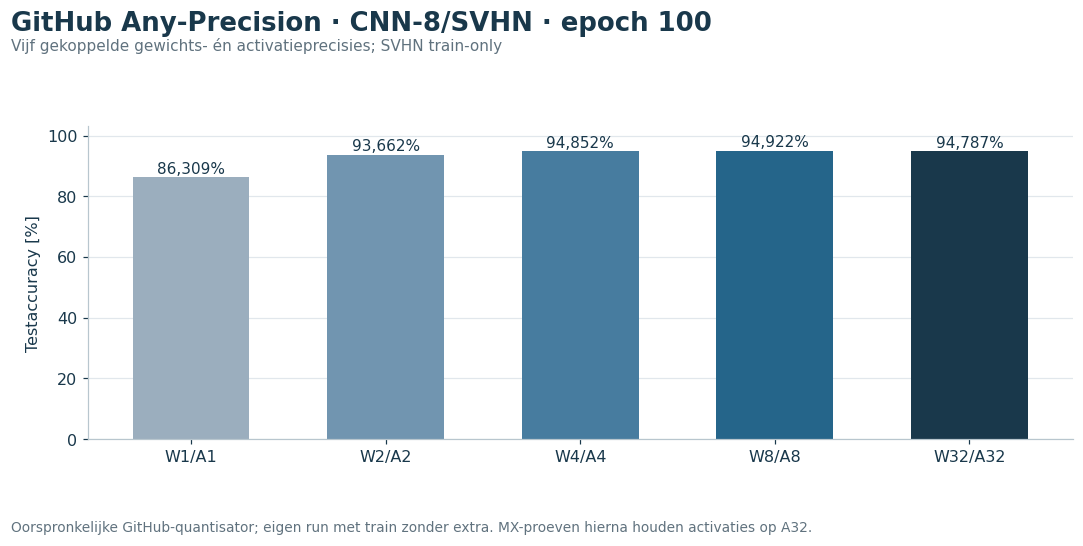

In [6]:
github_plot()
table(all_checkpoint_table().query("Training == 'GitHub Any-Precision · 5 modi'"), 'Exacte GitHub-eindpunten')


**Waarneming:** W1/A1 blijft duidelijk achter. W4/A4, W8/A8 en W32/A32 liggen in deze run dicht bij elkaar. Meer bits geven in een gezamenlijk getraind netwerk niet automatisch de hoogste gemeten accuracy. Dit is één uitvoering; verschillen van enkele testbeelden zijn geen bewezen algemeen rangorde-effect.


## 2.1 Volledig verloop: vijf GitHub-modi

De volgende figuur toont de **testaccuracy na elk van de 100 epochs** voor de vijf modi van dezelfde gezamenlijke training. Alle meetpunten blijven ongewijzigd en de curves worden niet afgevlakt. De hoofdweergave bevat de volledige gemeten waardeband; de aparte detailweergave zoomt alleen de verticale as in en blijft alle 100 epochs tonen.


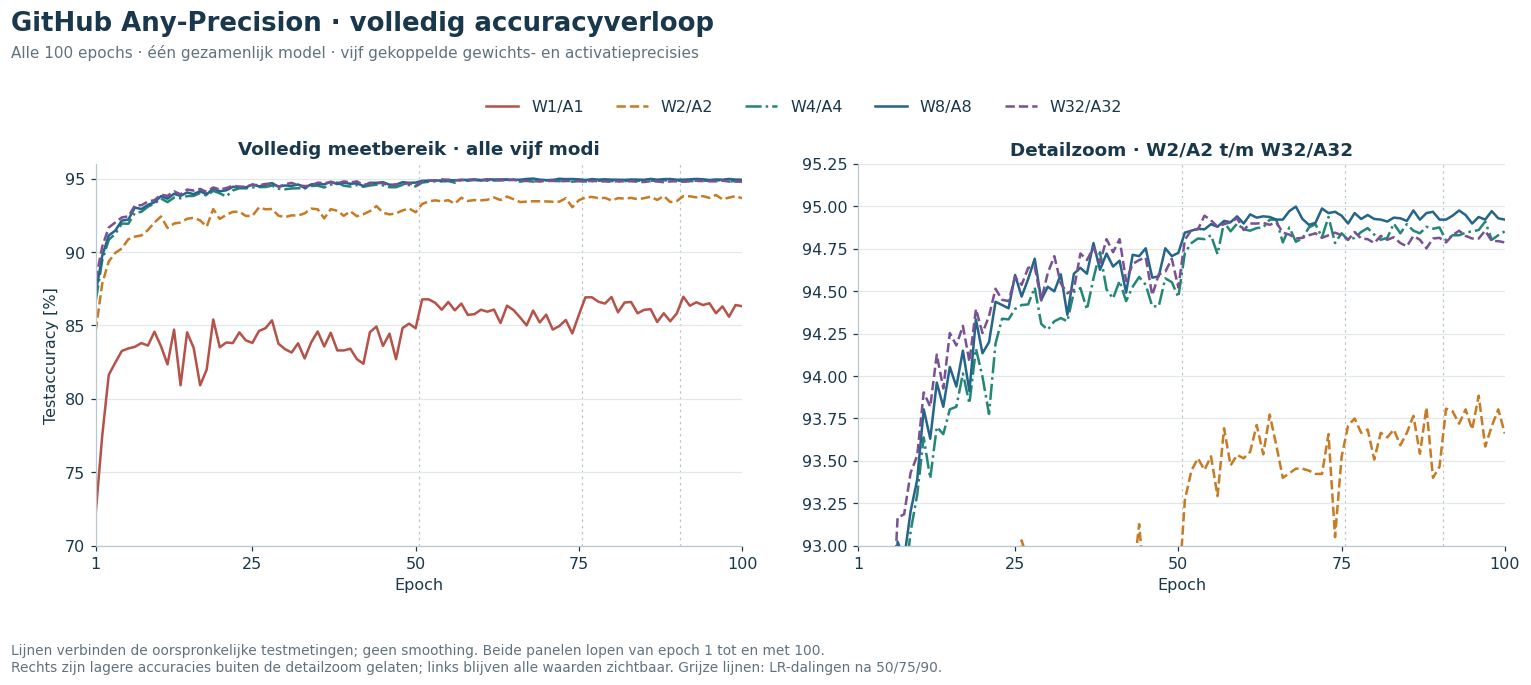

In [7]:
github_training_curve_plot()


<a id="dual"></a>
# 3. Twee MX-precisies: dedicated, gezamenlijk direct en mantissatruncatie

De categorie **dedicated per formaat** bevat twee afzonderlijke trainingen. De andere categorieën zijn elk één gezamenlijk model met E2M3/A32 en E2M1/A32. In de directe variant wordt elke precisie rechtstreeks uit de effectieve mastergewichten bepaald. In de truncatievariant komt de lage modus uit de opgeslagen hoge MX-codes, met behoud van hun schaal.


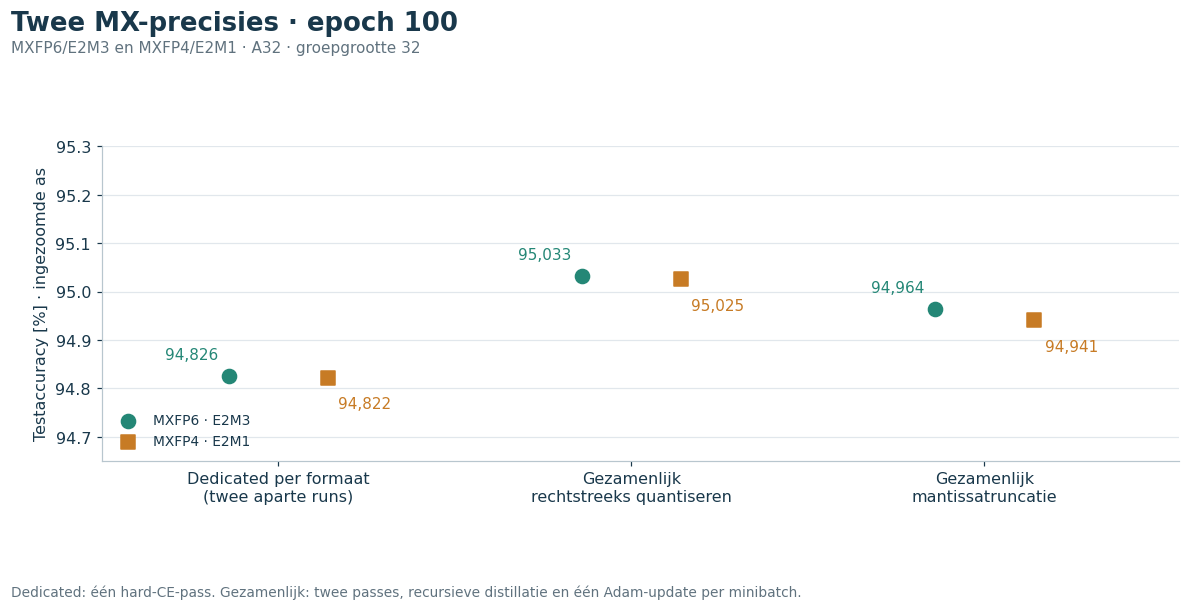

In [8]:
dual_plot()
table(checkpoint_table(['dedicated','dual_direct','dual_mantissa'], bits=(6,4)), 'Epoch 100: twee MX-precisies')


**Waarneming:** gezamenlijk direct scoort op epoch 100 ongeveer 95,03% in beide modi. Truncatiebewuste training eindigt op 94,964% / 94,941% en maakt één E2M3-bron bruikbaar voor beide gewichtsmodi. De dedicated-referenties liggen op 94,826% / 94,822%. Het verschil tussen dedicated en gezamenlijk omvat ook distillatie, mode-specifieke BN-aanpassing en meer passes per optimizerupdate.


## 3.1 Volledig verloop: dedicated, direct en mantissatruncatie

Per uitvoerprecisie vergelijken we de oorspronkelijke testmetingen na **epochs 1–100**. De dedicated lijnen komen uit twee afzonderlijke trainingen. Elke gezamenlijke variant levert beide precisies uit één training. De mantissatruncatie is bij de betreffende trainingsvariant vanaf het begin actief; deze curves zijn geen achteraf geconstrueerde A/B/C-reeksen.


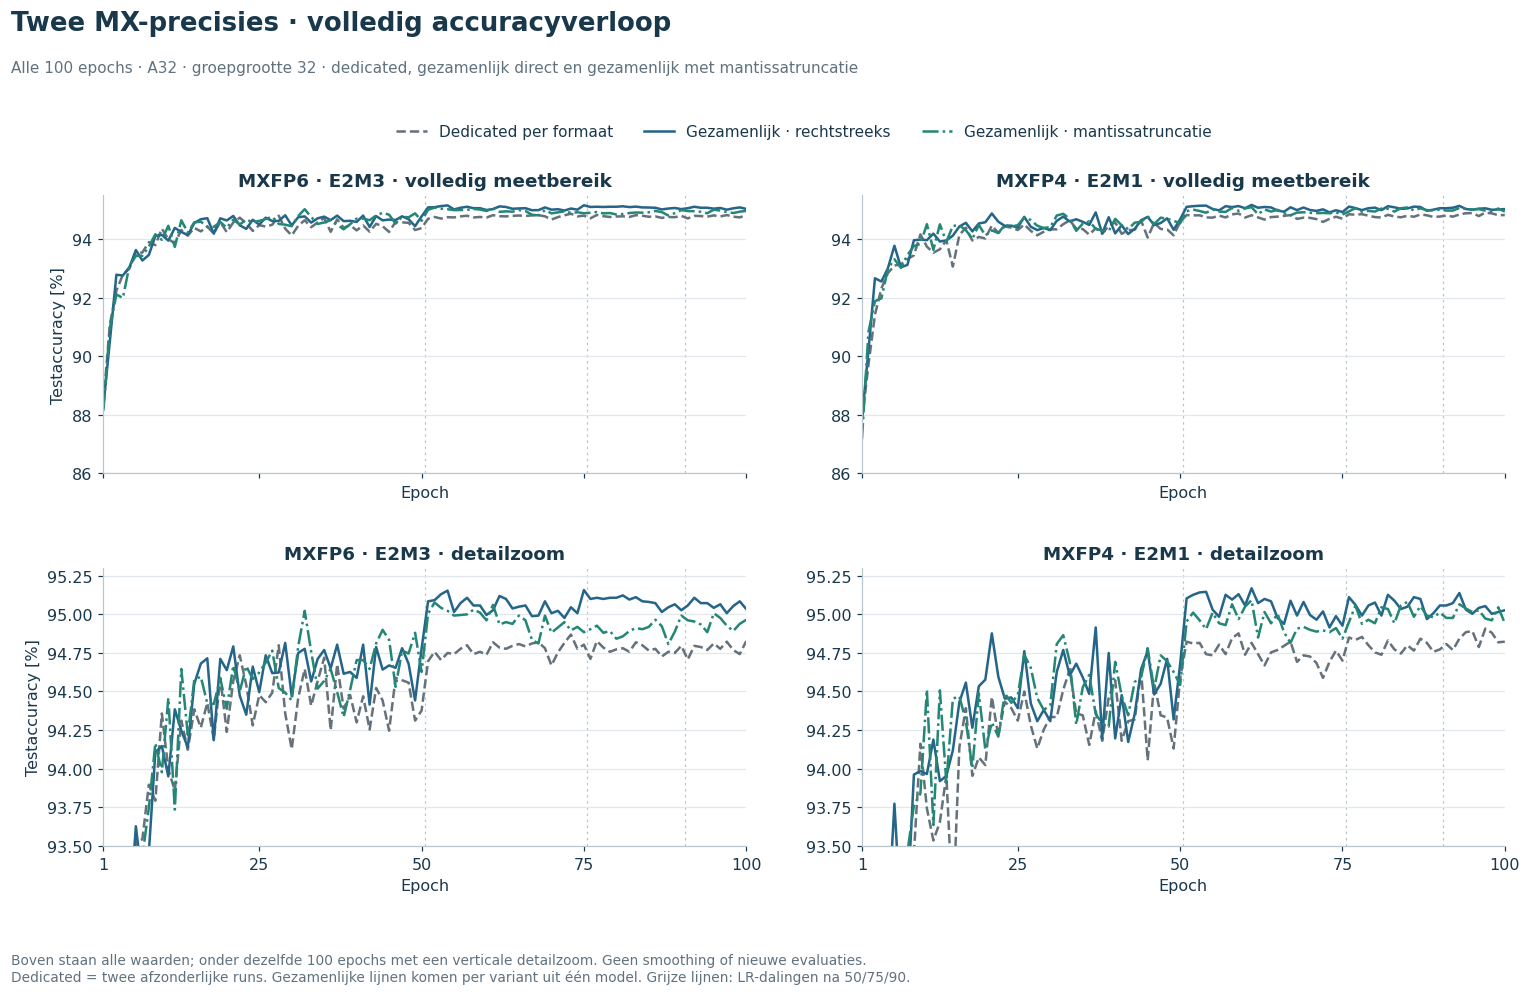

In [9]:
dual_training_curve_plot()


<a id="triple"></a>
# 4. Drie MX-precisies: het volledige trainingsoverzicht

Alle onderstaande scores zijn de **oorspronkelijk geregistreerde testaccuracies na epoch 100**. Latere herhaalde posthoc-evaluaties vervangen deze scores niet. De rij met dedicated-resultaten combineert drie aparte modellen; elke andere rij biedt de drie modi binnen één gezamenlijk model.

**Freeze na 50** betekent: dezelfde geleerde training tot en met epoch 50, vervolgens alleen de offsetwaarden vastzetten tijdens epochs 51–100 terwijl de gewichten blijven leren. De rest van de training is dus wél afgerond tot epoch 100.


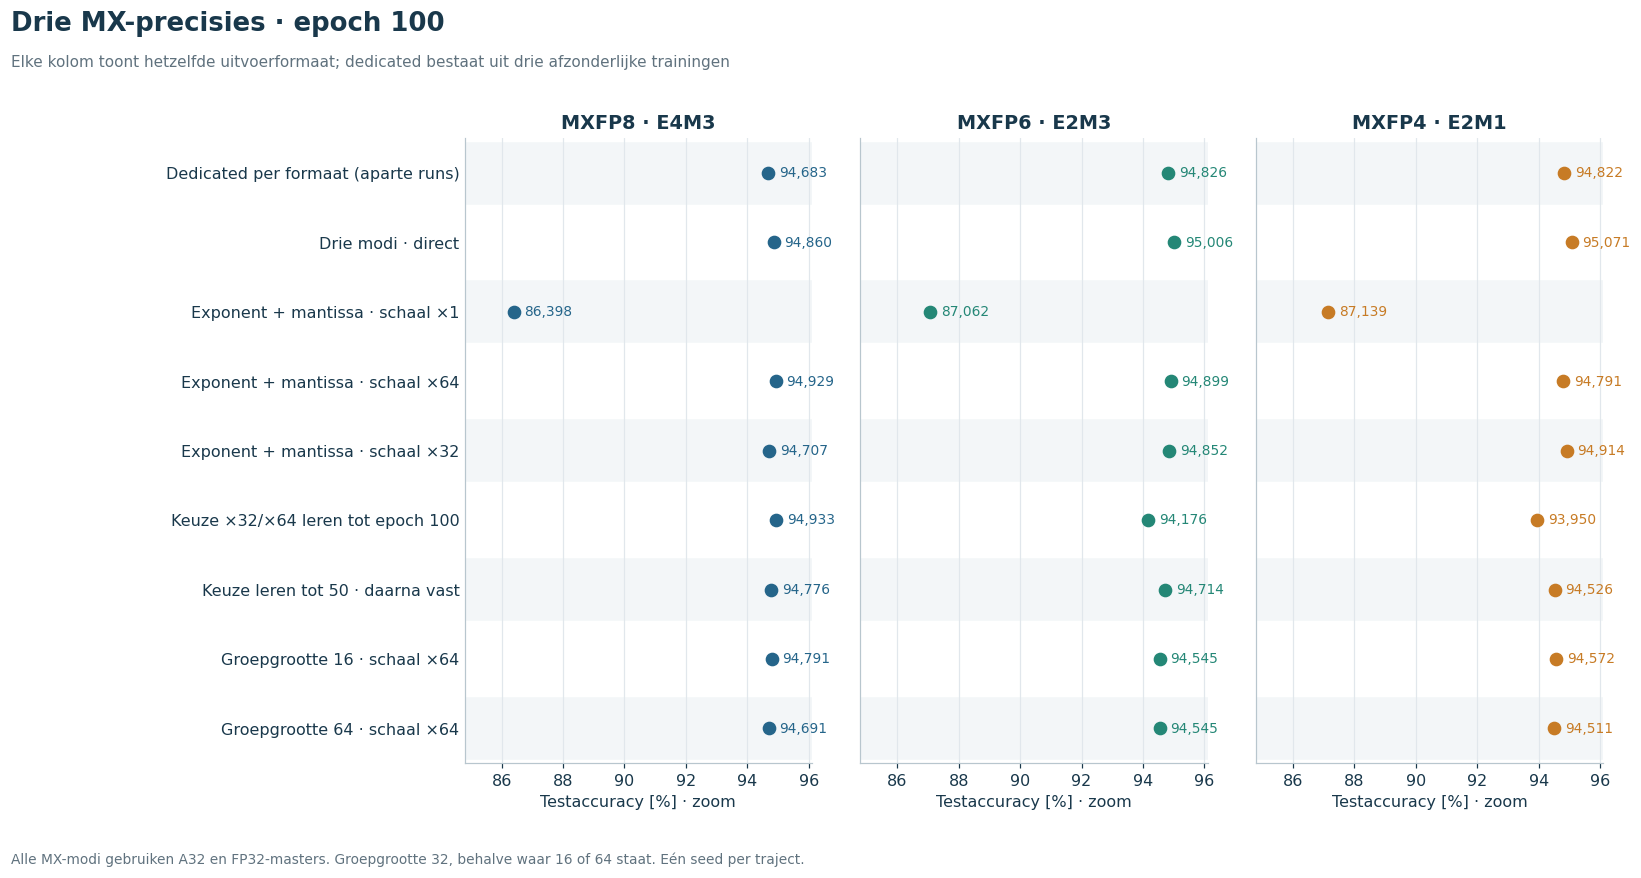

**Alle drieprecisie-eindpunten**

,Training,Epoch,E4M3 [%],E2M3 [%],E2M1 [%]
0,Dedicated per formaat (aparte runs),100 / 100 / 100,94.683466,94.825599,94.821758
1,Drie modi · direct,100,94.860172,95.006146,95.071451
2,Exponent + mantissa · schaal ×1,100,86.397511,87.062077,87.138906
3,Exponent + mantissa · schaal ×64,100,94.929318,94.898586,94.791026
4,Exponent + mantissa · schaal ×32,100,94.706515,94.852489,94.913952
5,Keuze ×32/×64 leren tot epoch 100,100,94.933159,94.176398,93.949754
6,Keuze leren tot 50 · daarna vast,100,94.775661,94.714198,94.525968
7,Groepgrootte 16 · schaal ×64,100,94.791026,94.545175,94.572065
8,Groepgrootte 64 · schaal ×64,100,94.691149,94.545175,94.510602


In [10]:
triple_plot()
table(checkpoint_table(TRIPLE_IDS), 'Alle drieprecisie-eindpunten', force=True)


De naïeve exponentroute met dezelfde bronschaal kan tijdens training gedeeltelijk worden opgevangen, maar alle drie modi blijven hier rond 86–87%. De vaste schaalvarianten brengen de scores terug naar ongeveer 95%. Omdat die verschillen veel groter zijn dan de verschillen tussen de betere varianten, volgt dezelfde vergelijking nogmaals ingezoomd.


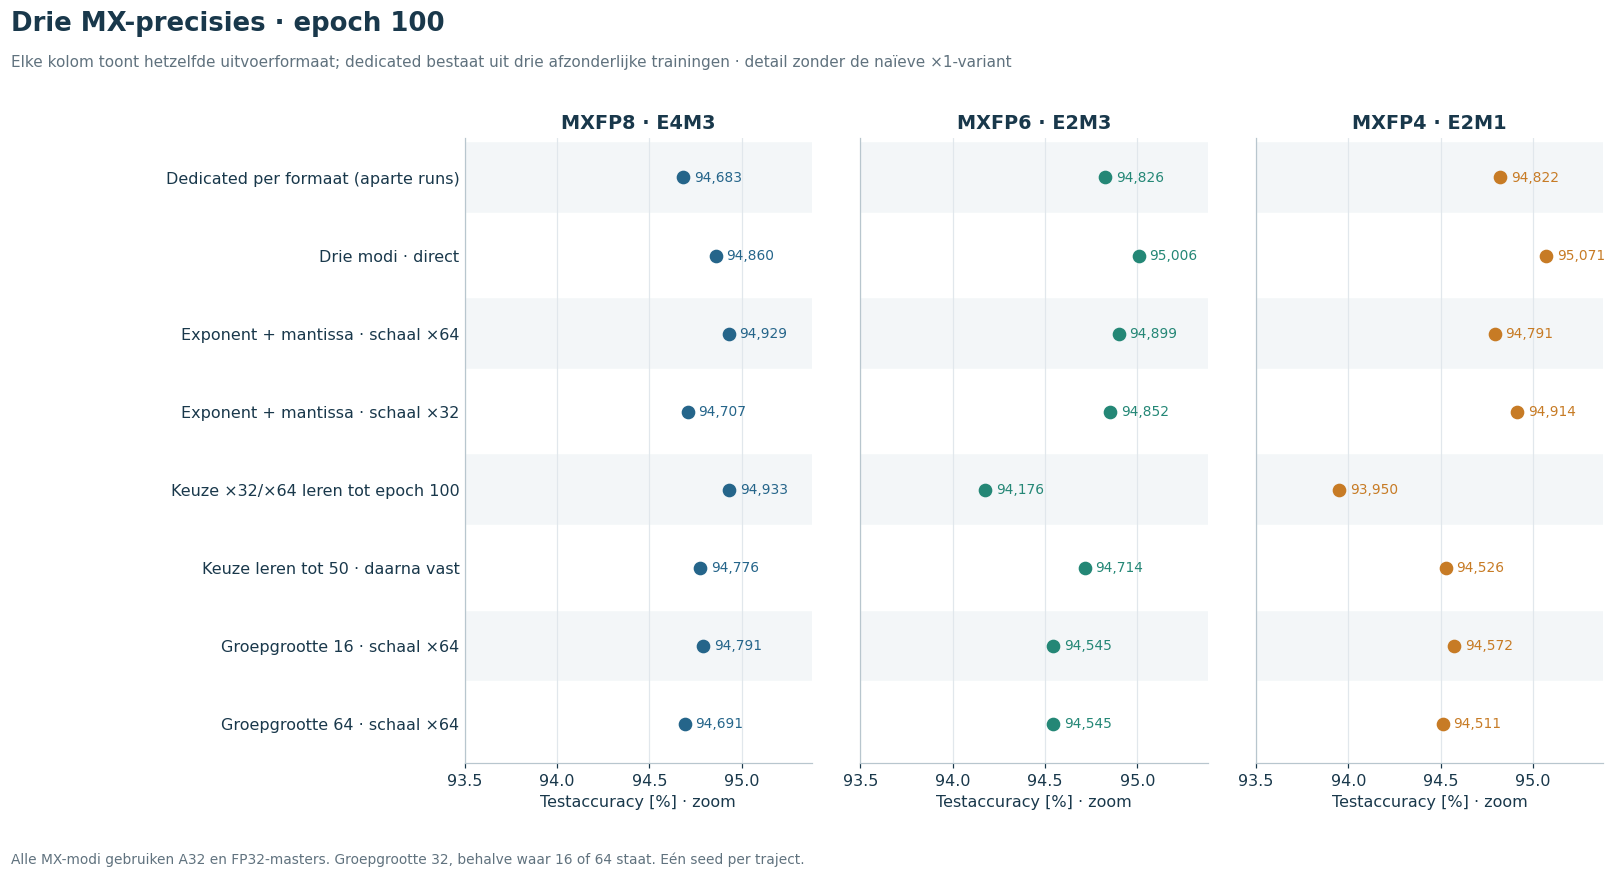

In [11]:
triple_plot(detail=True, name='03b_triple_epoch100_detail')


**Wat deze tabel wel laat zien:** triple-direct heeft de hoogste E2M3/E2M1-eindscores van de triple-trajecten, maar vereist voor exact dezelfde directe uitvoerwaarden meerdere codesets of requantisatie vanuit een uitgebreidere bron. De vaste ×32/×64-routes ondersteunen bittruncatie uit één E4M3-bron. Learned tot 100 verbetert de lagere precisies hier niet; freezen na 50 herstelt een deel van die achterstand. Geen van deze verschillen is met meerdere seeds bevestigd.


## 4.1 Volledig verloop: alle drieprecisievarianten

De drie kolommen volgen E4M3, E2M3 en E2M1 over **alle 100 epochs**, met dezelfde varianten als het eindpuntenoverzicht. De bovenste rij bevat alle gemeten waarden, inclusief de lagere naïeve route; de onderste rij is een expliciete verticale detailzoom. Punten buiten die detailzoom blijven zichtbaar in de hoofdweergave. De learned100- en freeze-na50-curves delen exact epochs 1–50, omdat freeze vanaf dat checkpoint vertakt.

Deze drie nieuwe verloopfiguren gebruiken uitsluitend de bestaande traininglogs. De posthocproeven in hoofdstuk 5 zijn alleen op bepaalde opgeslagen checkpoints uitgevoerd; er is geen gemeten posthocreeks voor elke epoch.


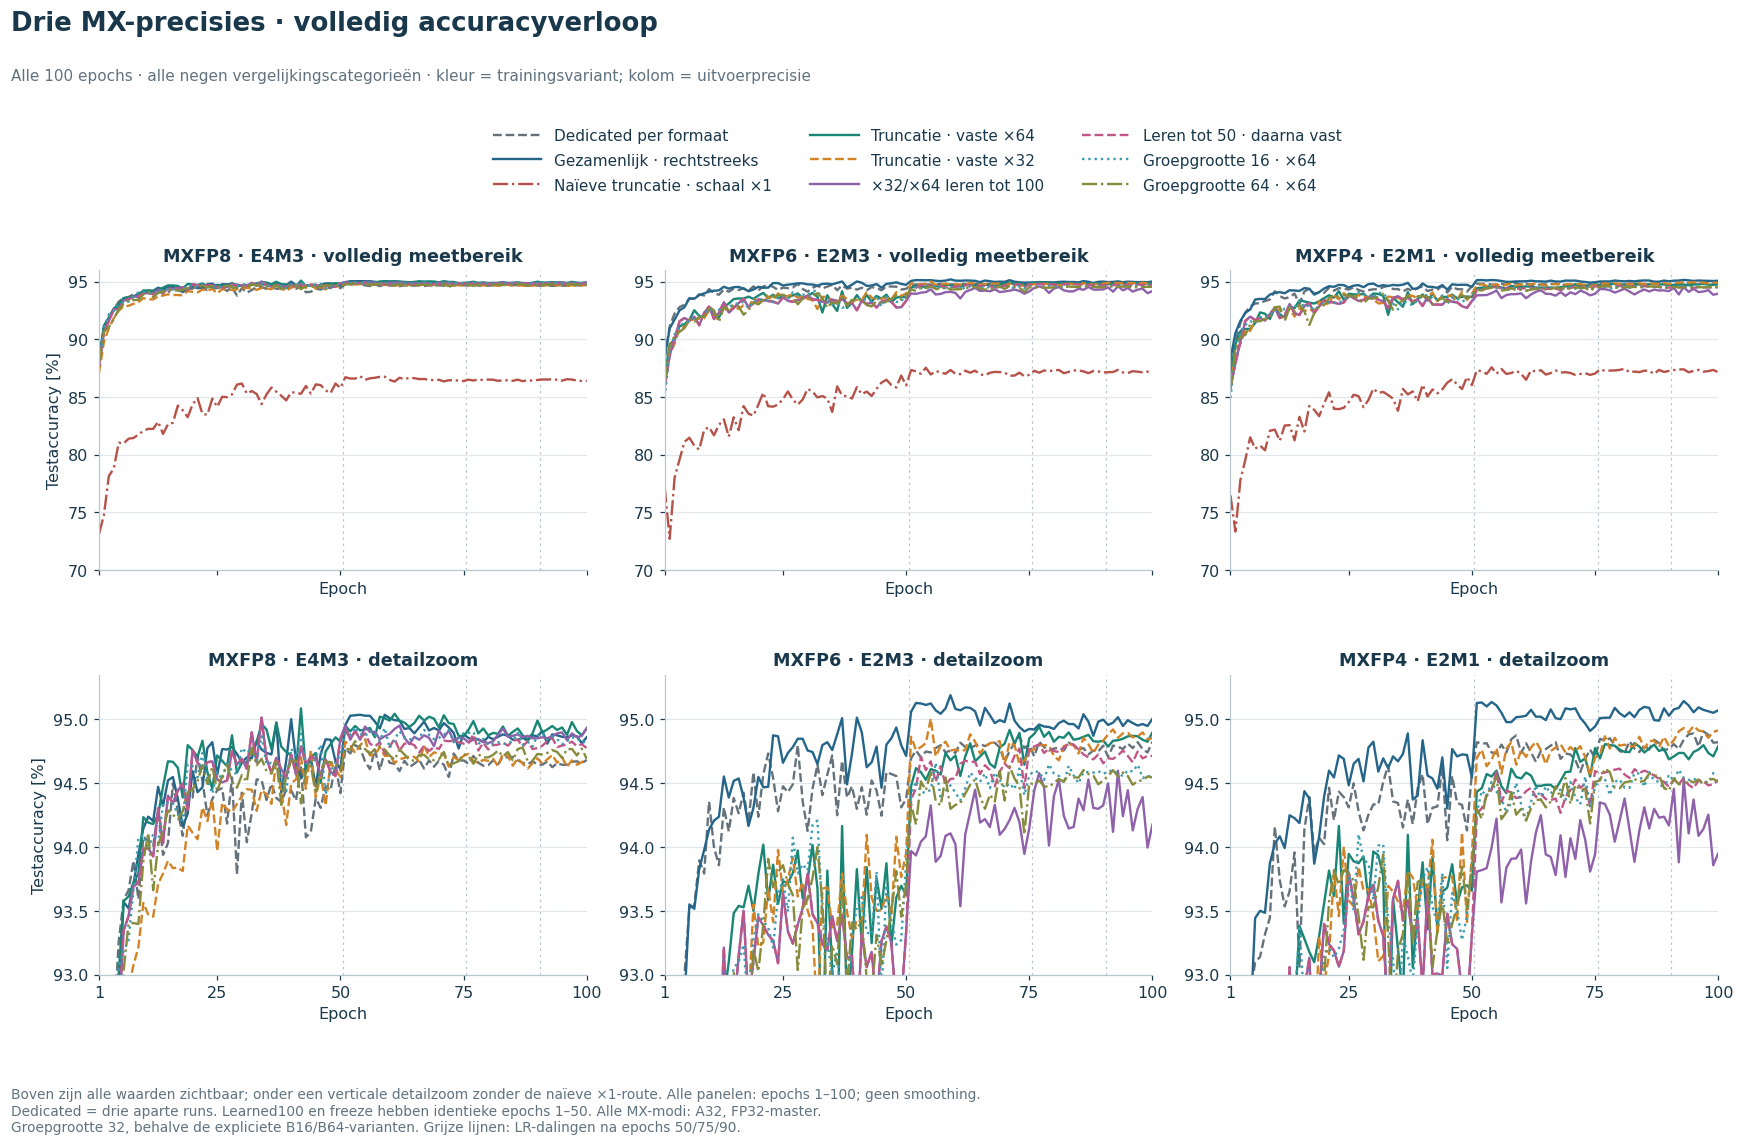

In [12]:
triple_training_curve_plot()


<a id="posthoc"></a>
# 5. Achteraf toepassen tegenover ermee trainen

**Posthoc** betekent hier: een bestaande training en een vast checkpoint laden, de gewichtsroute veranderen en opnieuw evalueren. Er zijn **geen optimizerupdates en geen BN-herkalibratie**. De bestaande BN-bank blijft bevroren: bij W32 → MXFP6 de W32-bank, bij de latere A/B/C-proeven de doelprecisiebank.

Binnen één posthocproef delen de vergelijkingspaden hetzelfde checkpoint. Een daarnaast getoonde training met quantisatie of truncatie heeft een **ander getraind model**, waarbij ook de BN-statistieken zich hebben aangepast. Dit onderscheid staat in de labels en brongegevens.

## 5.1 MXFP6-quantisatie toevoegen

De eerste conversieproef vertrekt alleen van de **W32/A32-modus van het vijfmodusmodel**. Posthoc MXFP4 en MX-activaties op die bron zijn niet uitgevoerd en krijgen daarom geen ingevulde meetwaarde.

### Waarom zijn GitHub W32/A32 en dedicated W32/A32 verschillende referenties?

| Referentie | Hoe werd het model getraind? | Wat wordt hier geëvalueerd? |
|---|---|---|
| GitHub W32/A32 | Eén gedeeld model, gezamenlijk voor W32/A32, W8/A8, W4/A4, W2/A2 en W1/A1; vijf passes per minibatch. | Alleen de W32/A32-modus van dat gezamenlijk getrainde model. |
| Dedicated W32/A32 | Een afzonderlijke training vanaf initialisatie, uitsluitend W32/A32 met hard-label CE; één pass per minibatch. | De enige actieve W32/A32-modus van die controletraining. |

In de gezamenlijke GitHub-training gebruikt W32 hard-label CE en gebruiken de lagere modi de losgekoppelde voorspelling van de voorafgaande modus als teacher. Alle vijf bijdragen werken op de gedeelde mastergewichten, vóór één Adam-update. Dedicated krijgt alleen de bijdrage van W32. Beide behouden de oorspronkelijke gewichtsvoorbewerking `G(W)`; de dedicated controle is dus niet ongemerkt een andere ruwe FP32-convolutie.

De eerste twee rijen van de figuur delen hetzelfde checkpoint: eerst de oorspronkelijke W32-route, daarna MXFP6 achteraf. De overige rijen komen uit aparte trainingen.


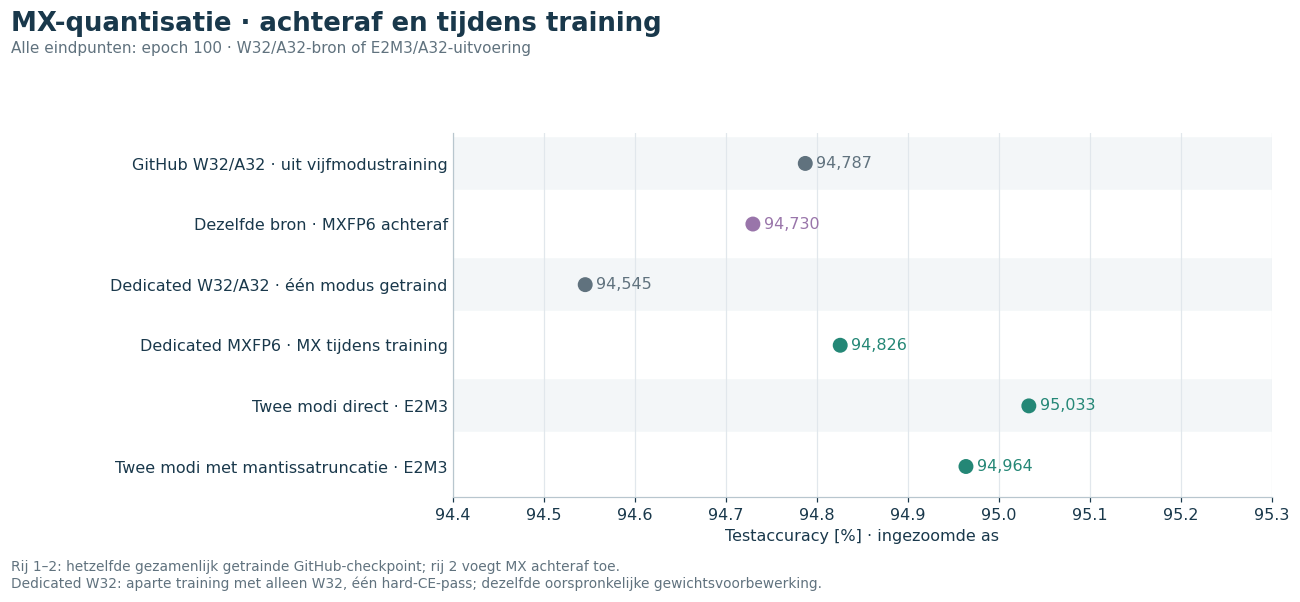

In [13]:
mx_posthoc_plot()


Op epoch 100 verandert W32/A32 → MXFP6 van **94,787% naar 94,730%**: 15 minder correcte voorspellingen. Op het geselecteerde epoch 54 is de MXFP6-conversie juist vier testbeelden beter. Dat ondersteunt een kleine conversie-impact in deze proef, maar bewijst geen algemene verbetering door quantisatie. De dedicated W32-controle is een aparte hard-CE-training en mag niet met de W32-modus uit de vijfmodustraining worden vereenzelvigd.

## 5.2 Mantissatruncatie: A/B/C op dezelfde tweemodusbron

**A, B en C zijn alle drie achteraf geëvalueerd op hetzelfde checkpoint van het direct getrainde tweemodusmodel.** Tijdens deze evaluaties zijn er geen optimizerupdates en blijft de E2M1-BN-bank bevroren.

| Rij | Route tijdens de evaluatie | Had het bronmodel deze route tijdens training? |
|---|---|---|
| A | E2M1 rechtstreeks uit de effectieve mastergewichten bepalen. | Ja: dit is de oorspronkelijke directe E2M1-route, achteraf opnieuw gemeten. |
| B | De E2M3-bron decoderen en opnieuw naar E2M1 afronden. | Nee: deze route wordt achteraf ingevoerd. |
| C | De twee laagste mantissabits uit de E2M3-codes verwijderen. | Nee: deze bittruncatie wordt achteraf ingevoerd. |
| Laatste rij | E2M1 via mantissatruncatie van E2M3. | Ja, in een **andere training** die vanaf het begin deze truncatieroute gebruikt. |

Alle A/B/C-routes gebruiken dezelfde schalen en doel-BN-bank. Alleen de laatste rij laat zien hoeveel een afzonderlijk met truncatie getraind model kan herstellen; daar hebben zowel de gewichten als de BN-statistieken zich tijdens training kunnen aanpassen.


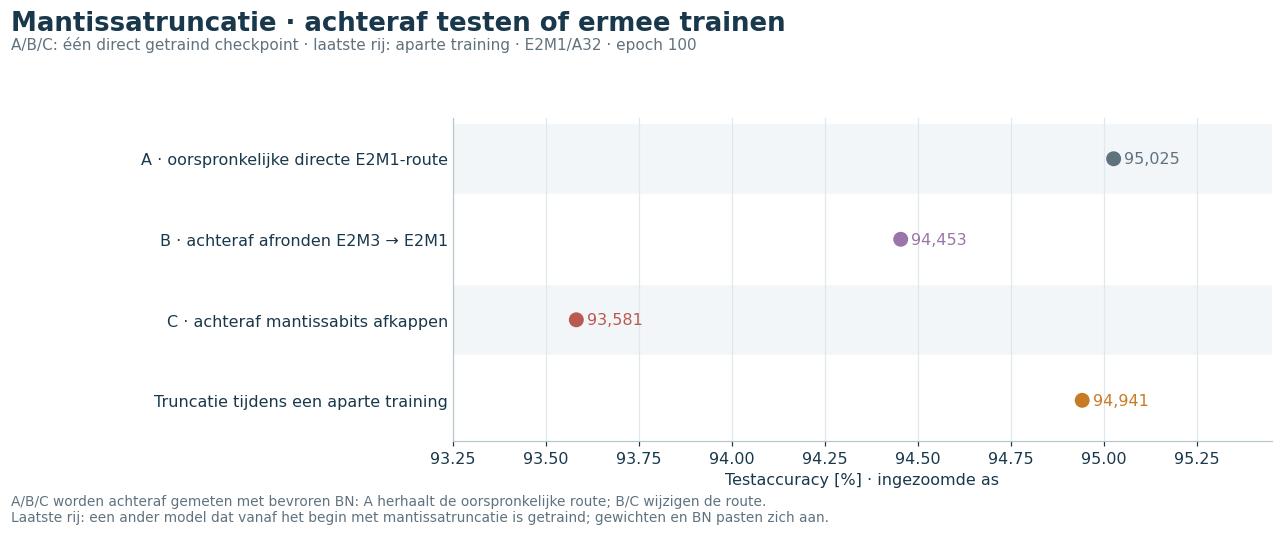

In [14]:
mantissa_plot()


De bittruncatie achteraf verlaagt de E2M1-score van **95,025% naar 93,581%**. De training met mantissatruncatie behaalt **94,941%**. Dit laat zien dat voorbereiding tijdens training veel van het verlies kan opvangen. A/B/C helpt afronding en truncatie uit elkaar te houden; het is geen unieke causale opsplitsing van alle effecten.

## 5.3 Mantissa en exponent achteraf op dezelfde drieprecisiecheckpoints

Na toevoeging van E4M3 hebben we de mantissaproef opnieuw uitgevoerd op **dezelfde triple-direct-checkpoints als de exponentproef**. Zo wordt een verschil tussen brontrainingen niet verward met het verschil tussen bitbewerkingen.

**Alle acht rijen van de volgende figuur zijn evaluaties achteraf van één vast checkpoint.** De eerste drie rijen herhalen de oorspronkelijke directe E4M3-, E2M3- en E2M1-routes waarvoor dat gezamenlijke model getraind was. De vijf overige rijen vervangen de gewichtsroute achteraf door afronding of bittruncatie. Tijdens geen van deze acht metingen wordt verder getraind of BN opnieuw gekalibreerd. De vergelijking met modellen die wél met exponenttruncatie zijn getraind, volgt in paragraaf 5.4.


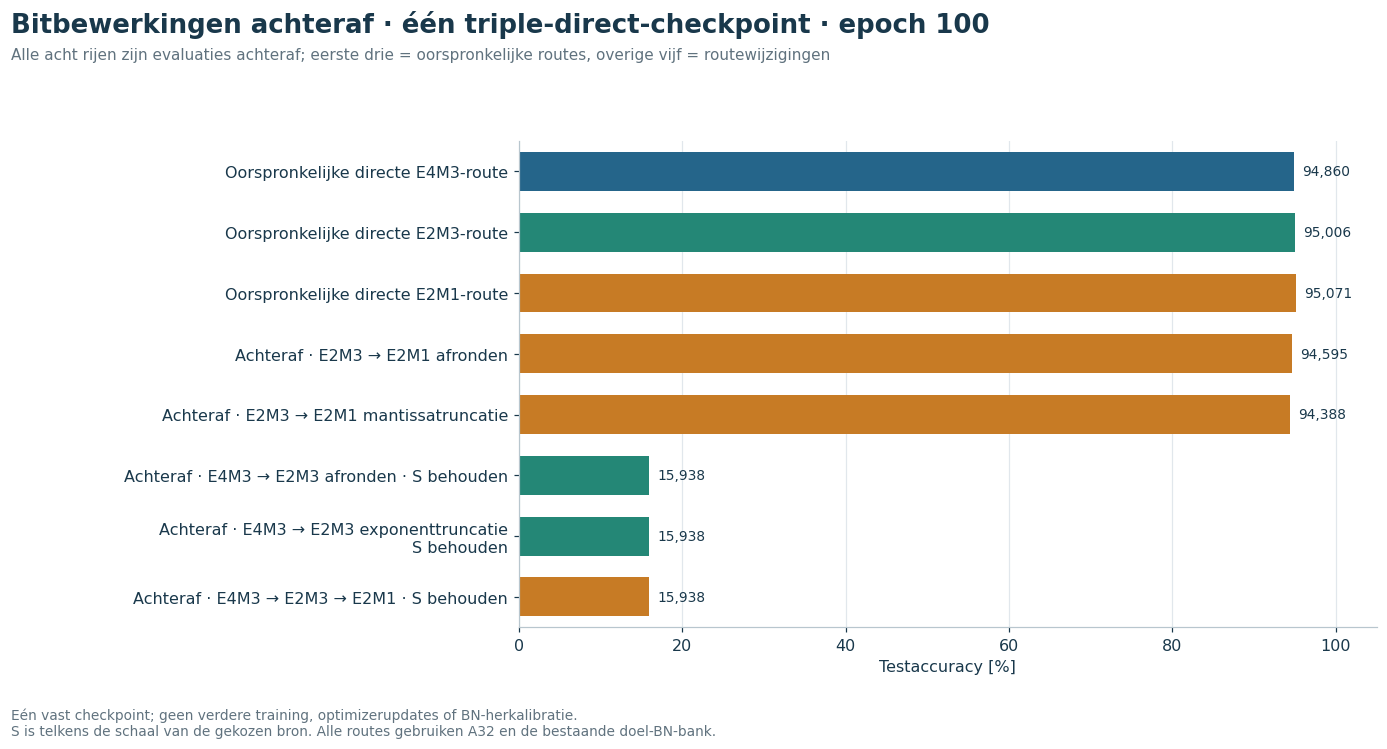

In [15]:
triple_posthoc_plot()


De E2M3→E2M1-mantissaroute blijft hier op **94,388%**. De E4M3→E2M3-exponentroute met de E4-bronschaal valt terug naar **15,938%**, evenals de gecombineerde lage route. Dit zijn gemeten uitkomsten op de volledige testset; de posthocproef verandert de getrainde BN-instellingen niet.

## 5.4 Naïeve exponenttruncatie en ×64: achteraf of tijdens training


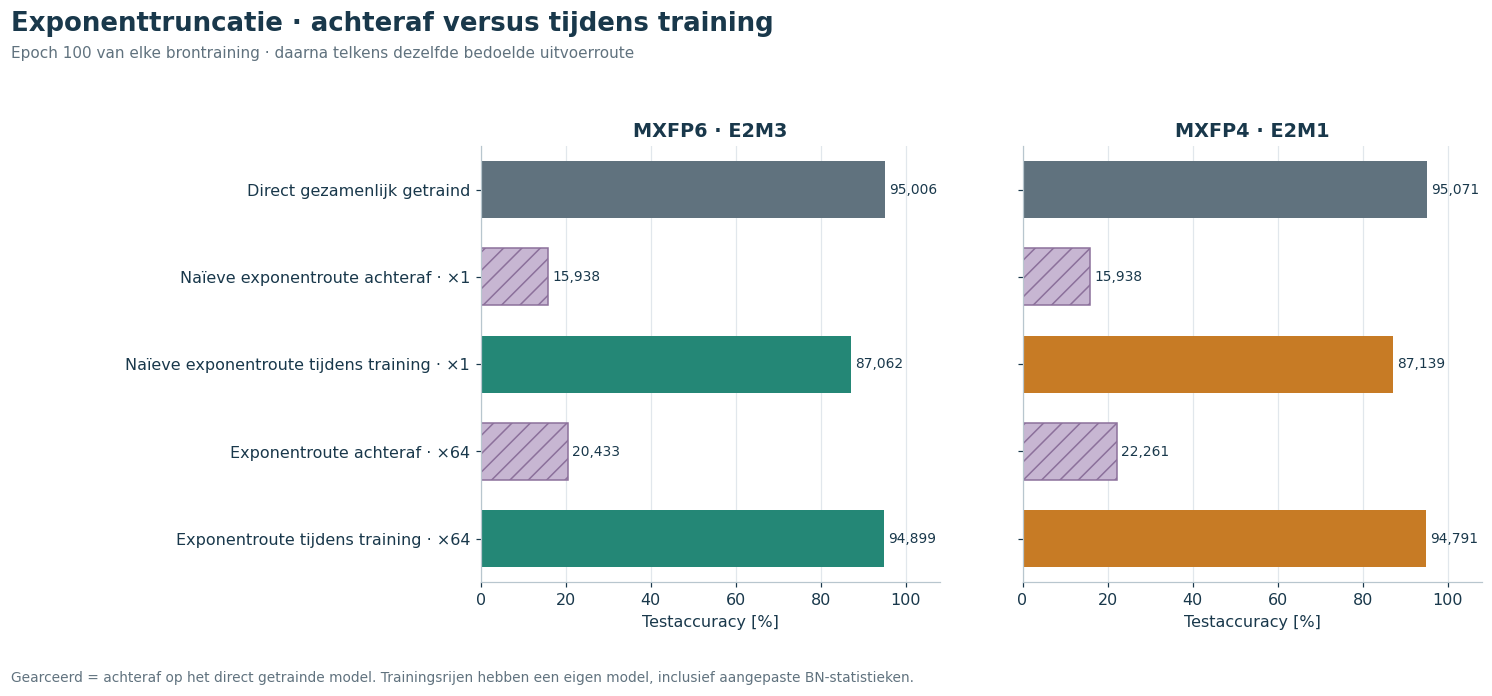

In [16]:
exponent_adaptation_plot()


Naïeve exponenttruncatie stijgt door training van ongeveer **15,94% naar 87,06% / 87,14%** in de lagere modi, maar blijft duidelijk achter bij directe quantisatie. Alleen achteraf ×64 toevoegen op de direct getrainde bron geeft hier **20,43% / 22,26%**. De eigen ×64-training behaalt **94,90% / 94,79%**. De precieze uitvoerconfiguratie waarop het model wordt getraind is dus bepalend in deze onderzochte trajecten.

## 5.5 Schaal en afronding apart controleren

De ×64-controle is ook op beide bestaande brontrainingen uitgevoerd. **A** behoudt de E4-bronschaal. **B** houdt exact dezelfde exponentbits maar gebruikt 64× die schaal. **C** rondt de **gedecodeerde E4M3-bron** af naar E2M3 bij die ×64-schaal; C4 ontstaat daarna door mantissatruncatie van C6. C is dus niet rechtstreeks afronden vanuit de FP32-master.


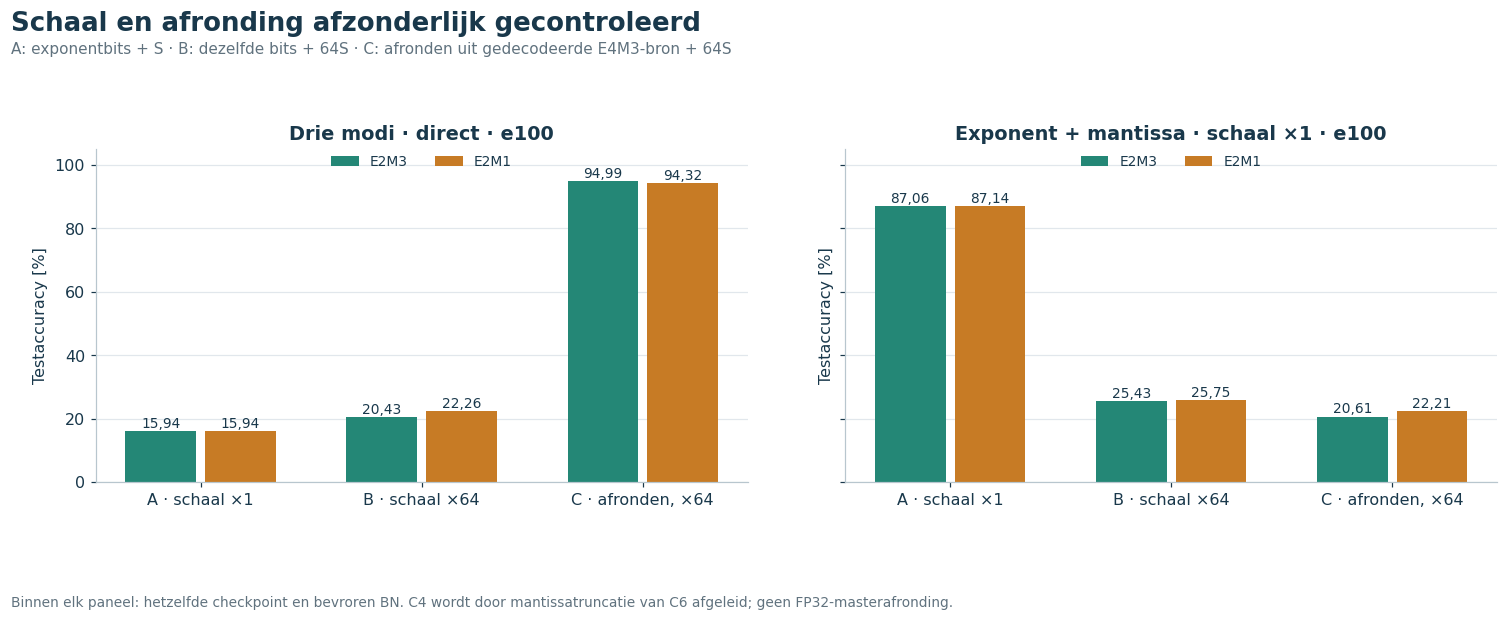

In [17]:
scale_control_plot()


Op de direct getrainde bron herstelt C6 tot **94,991%**, terwijl alleen de bits behouden met ×64 veel lager blijft. Op de naïef getrainde bron werkt dezelfde schaalwijziging juist slecht. Deze controles laten zien dat zowel de concrete codebewerking als de schaalrelatie en de trainingsconfiguratie relevant zijn. Zij maken ×64 niet automatisch tot een optimale schaalfactor.


<a id="leren"></a>
# 6. Geleerde schaalkeuzes en groepgrootte

## 6.1 Leren tussen ×32 en ×64

Per B32-groep is één FP32-hulpparameter \(\theta\in[5,6]\) gebruikt. De voorwaartse keuze schakelt bij 5,5 tussen de gehele offsets 5 en 6. Beide lagere modi delen die keuze. De benaderde schaalgradient is gebaseerd op \(\ln(2)\sum_i g_i\hat w_i\). De gewichtsgradient blijft via de bestaande identity-STE lopen.

De freeze-variant erft exact de eerste 50 epochs van learned100. Vanaf epoch 51 blijft de offsetwaarde gelijk. **De E4M3-bronschalen blijven dynamisch.**


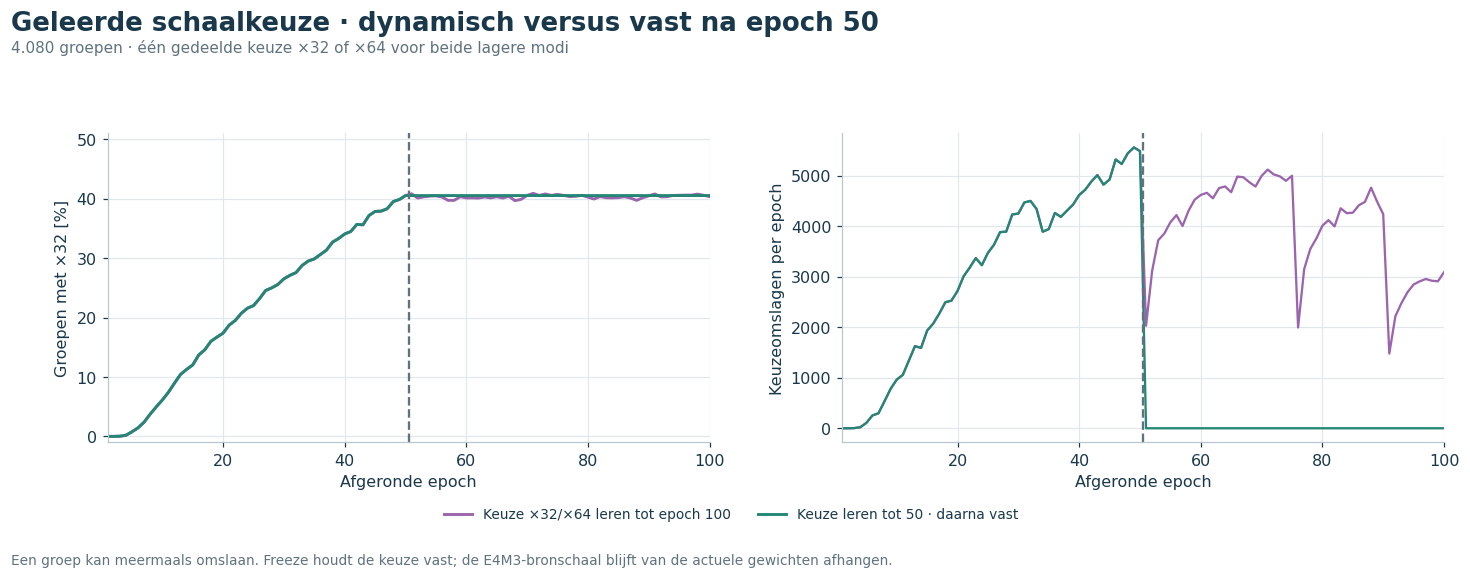

In [18]:
scale_learning_plot()


Op epoch 100 kiest learned100 **1.647 groepen ×32 en 2.433 groepen ×64**. Freeze behoudt de epoch-50-verdeling **1.654 / 2.426**. Learned100 registreert in epoch 100 nog **3.091 omslagen**, verspreid over 380 unieke groepen; een groep kan meermaals wisselen. Die observatie motiveerde het freeze-experiment, maar bewijst op zichzelf niet de oorzaak van de accuracyachterstand.

De volgende curves tonen het interval waarin de varianten uiteenlopen, naast de vaste factoren.


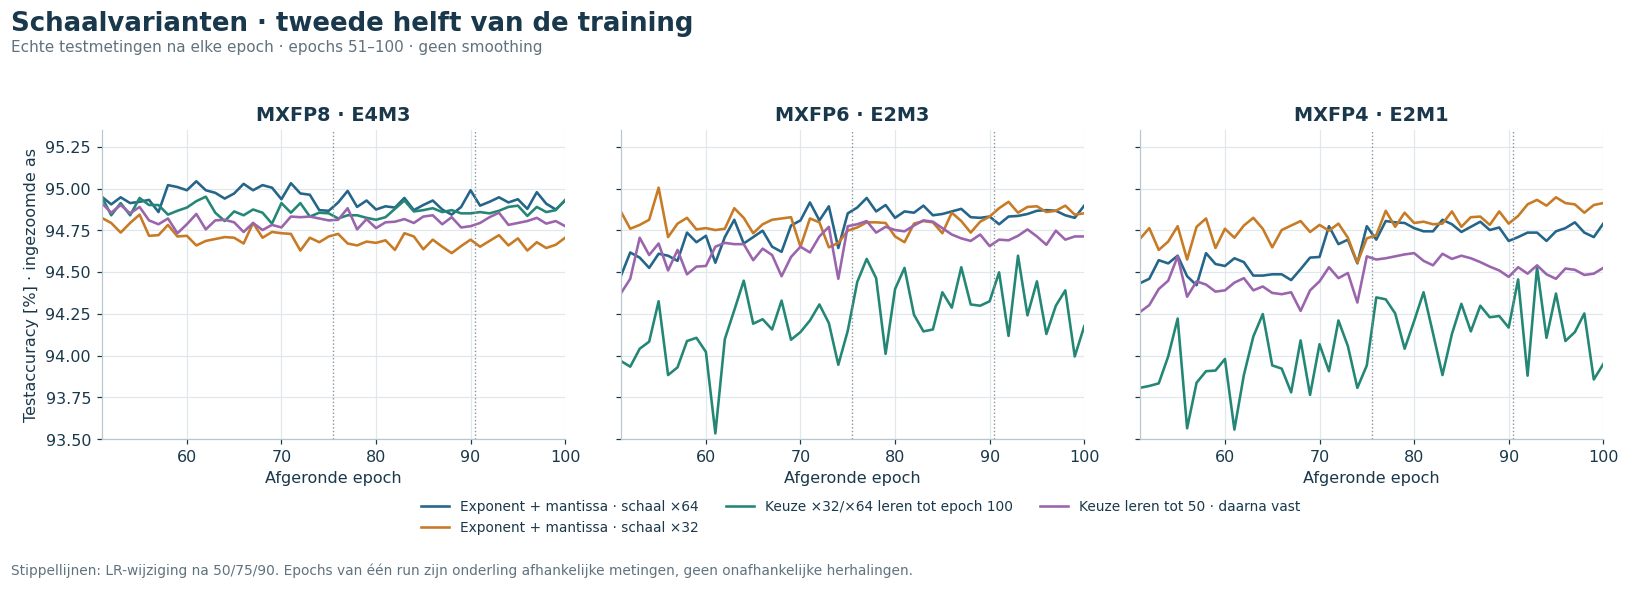

In [19]:
comparison_curves(['triple_scale64','triple_scale32','triple_learned100','triple_freeze50'], '10_schaalvarianten_curves_51_100', 'Schaalvarianten · tweede helft van de training', start=51, lower=93.5)


**Kostenrelevant:** freeze is geïmplementeerd met learning rate 0 voor theta. De schaalgradienten en Adam-momenten worden nog steeds berekend. Daardoor is dit experiment een onderzoek naar het effect van vaste keuzes, zonder een geoptimaliseerde vermindering van die trainingstaken.

## 6.2 Groepgrootte 16, 32 en 64

Alle drie behouden dezelfde vaste ×64-route. Op epoch 100 en in ieder epoch 76–100 scoort B32 in deze runs hoger bij alle drie precisies. De geselecteerde E4-checkpoints geven een andere lagere-precisierangorde, omdat B32 epoch 42 selecteert en B16/B64 epoch 53.


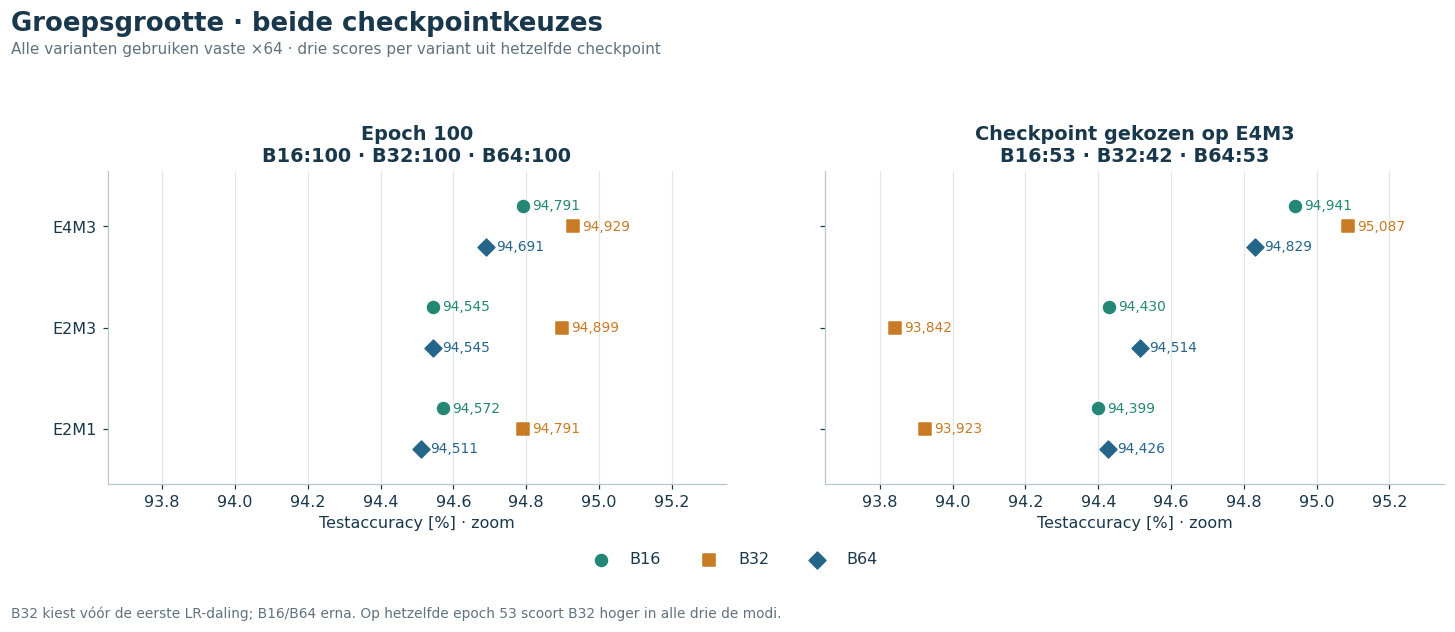

In [20]:
group_checkpoint_plot()


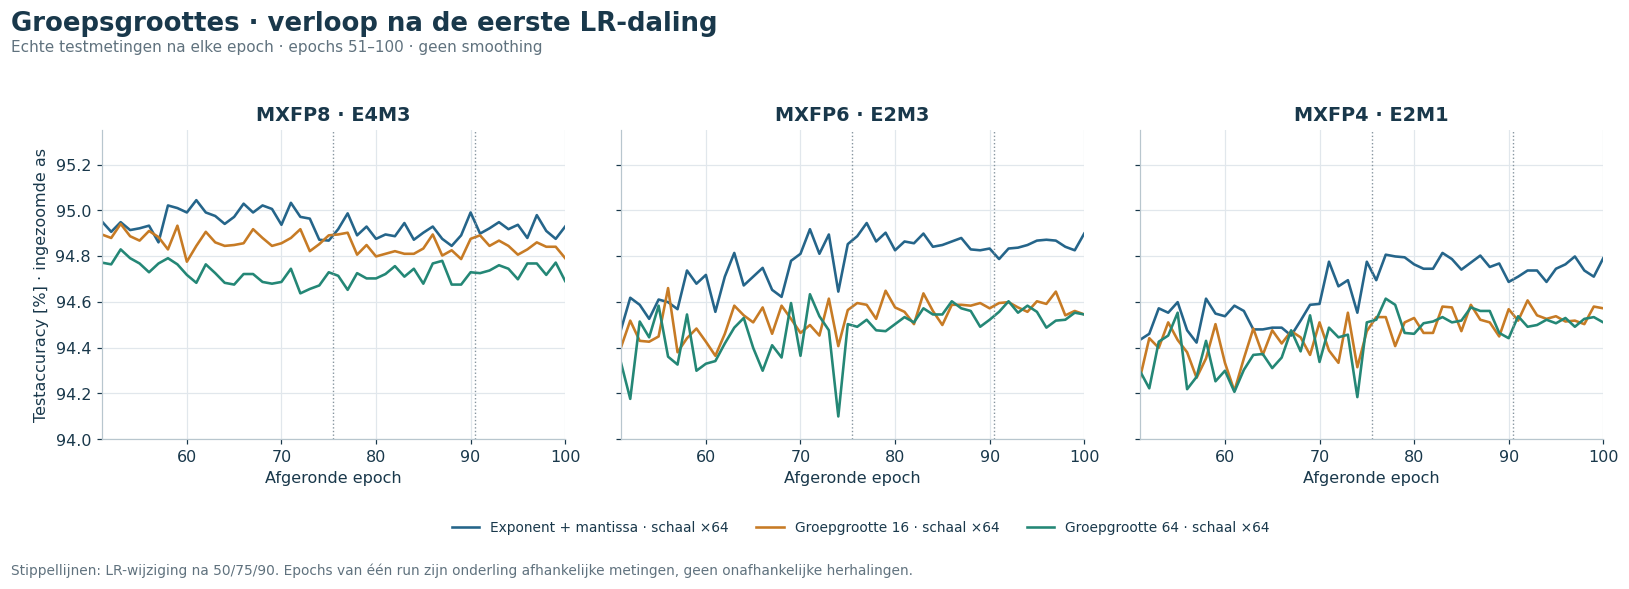

In [21]:
comparison_curves(['triple_scale64','triple_group16','triple_group64'], '11b_groepsgrootte_curves_51_100', 'Groepsgroottes · verloop na de eerste LR-daling', start=51, lower=94.0)


<a id="kosten"></a>
# 7. Opslag, trainingsstaat en looptijd

We onderscheiden vier verschillende grootheden:

| Grootheid | Vraag die ze beantwoordt |
|---|---|
| Actieve modelkopie | Hoeveel logische bytes vraagt één gekozen uitvoerprecisie? |
| Flexibele bron | Hoeveel blijvende broninhoud is nodig om twee of drie modi beschikbaar te houden? |
| Trainingsstaat | Hoeveel bytes vragen FP32-modeltensors, gradients en optimizer-momenten? |
| Werkelijke `.pt`-bestanden | Hoe groot rapporteerde de runner de geserialiseerde bestanden, inclusief metadata? |

Een lagere precisie in de gewichtsberekening betekent in de huidige emulator niet dat de update-master, activaties of alle werkbuffers ook compact opgeslagen worden. Geen van de onderstaande grafieken is een meting van native MX-energie of piek-VRAM.

## 7.1 Eén actieve modelkopie

De zes doellagen bevatten **129.472 echte gewichten**. De behouden eerste/laatste laag, biases en alle vijf BN-banken samen vragen **19.248 bytes**. Die bijstaat wordt consequent meegeteld; ongebruikte BN-banken worden niet stilzwijgend verwijderd.


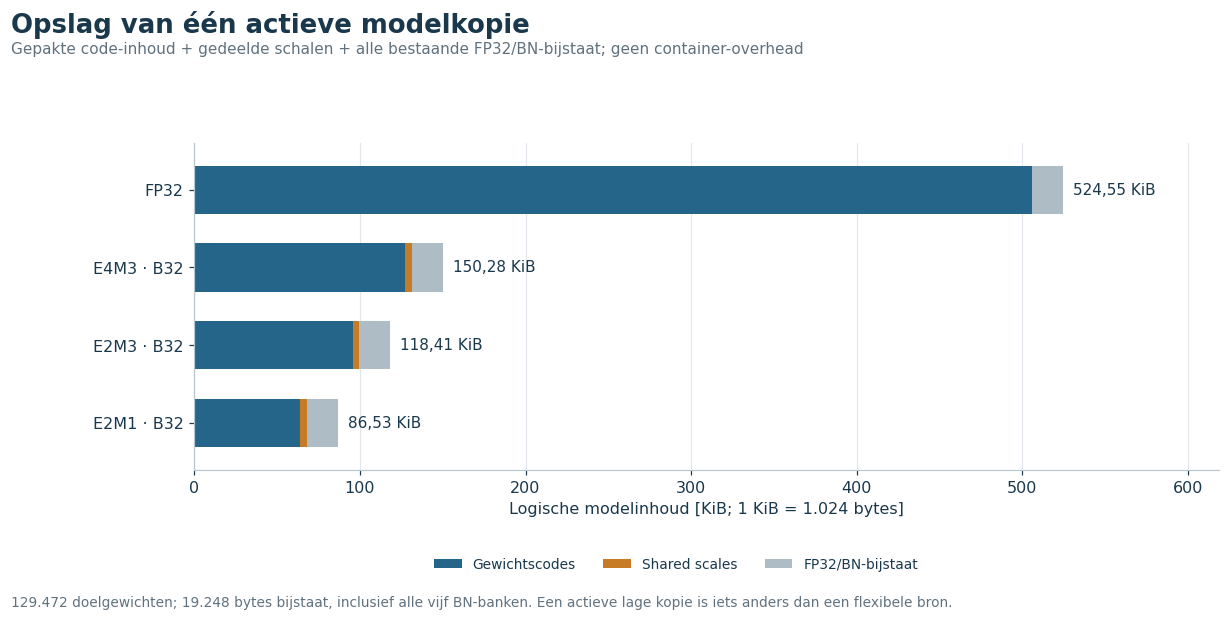

In [22]:
active_storage_plot()
table(pd.DataFrame(COST['active_layouts'])[['format','group_size','weight_payload_bytes','aux_bytes','total_model_bytes','compression_vs_fp32']], 'Exacte actieve layouts')


De totale B32-modelinhoud is **153.888 bytes voor E4M3**, **121.248 voor E2M3** en **88.608 voor E2M1**, tegenover **537.136 bytes** voor de FP32-modelstate. Directe quantisatie en truncatie hebben voor dezelfde actieve precisie dezelfde codebreedte; het onderscheid komt vooral naar voren bij de bron die meerdere modi ondersteunt.

## 7.2 Eén bron voor twee of drie modi

Een direct model bepaalt de formaten onafhankelijk vanuit de effectieve mastergewichten. Om de exact bedoelde directe uitvoerwaarden compact beschikbaar te houden, kunnen meerdere codesets bewaard worden. De figuur toont daarnaast de gunstige analytische variant waarin gezamenlijke modelbijstaat slechts eenmaal wordt bewaard. Voor dual zijn gelijke schaalarrays gecontroleerd en gedeeld; voor triple worden conservatief drie schaalarrays meegeteld.

Een truncatiebron bewaart de hoge codes en schalen en leidt de lagere waarden daaruit af. Bij een geleerde schaalkeuze komt **één keuze-bit per groep** erbij: 4.080 bits, oftewel **510 bytes**.


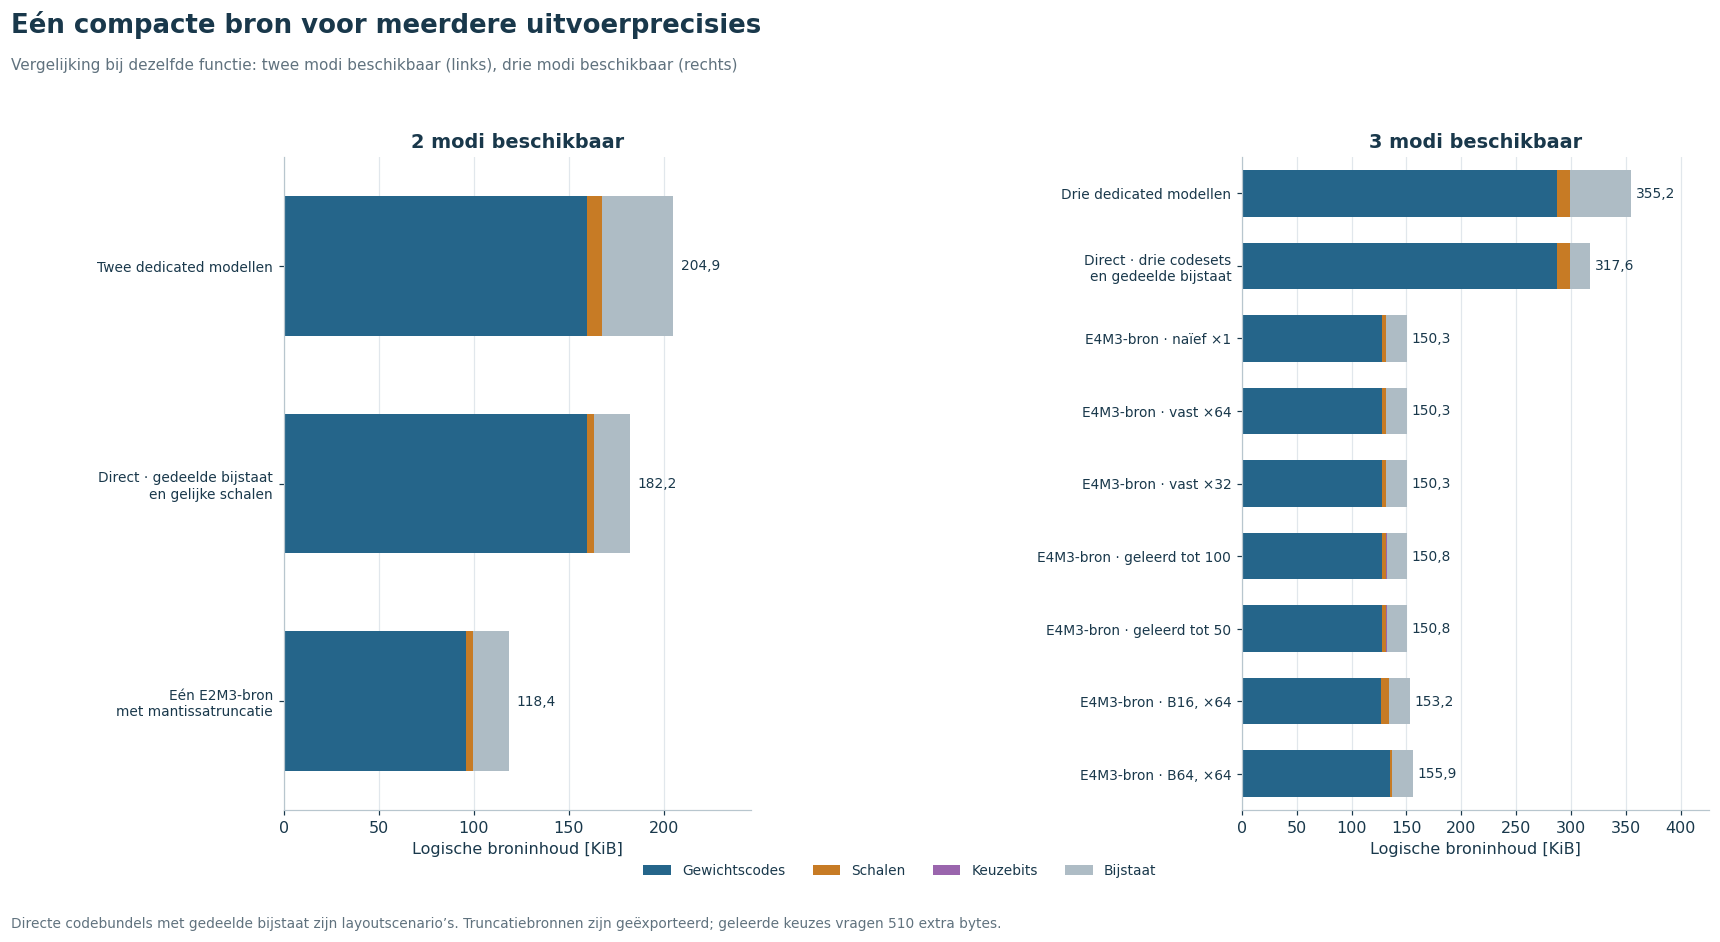

In [23]:
flexible_storage_plot()
table(pd.DataFrame(COST['flexible_sources'])[['label','total_bytes','implementation','evidence']], 'Alle bronopslagscenario’s')


Voor twee modi daalt de logische broninhoud van **186.528 bytes** voor de directe gedeelde-codebundel naar **121.248 bytes** voor één E2M3-truncatiebron. Voor drie modi is de vergelijking **325.248 bytes** voor de directe gedeelde-codebundel tegenover **153.888 bytes** voor één B32-E4M3-bron met vaste offset. De geleerde bron vraagt **154.398 bytes**.

De gedeelde directe multicode-container is een layoutberekening; de bestaande directe exporter schrijft zelfstandige bestanden. De source-only-proef voor dual heeft wel aangetoond dat de lage modus uit uitsluitend de hoge bron kan worden uitgevoerd. Voor triple registreren de exports exacte gereconstrueerde gewichten; latere volledige evaluaties staan bij de posthocmetingen.

Bij een **losse actieve lagere modus** zit de gekozen effectieve schaal al in de schaalbyte. Daar worden de 510 bronkeuzebytes niet nogmaals bovenop geteld.

## 7.3 Groepgrootte: minder schalen kan meer padding betekenen


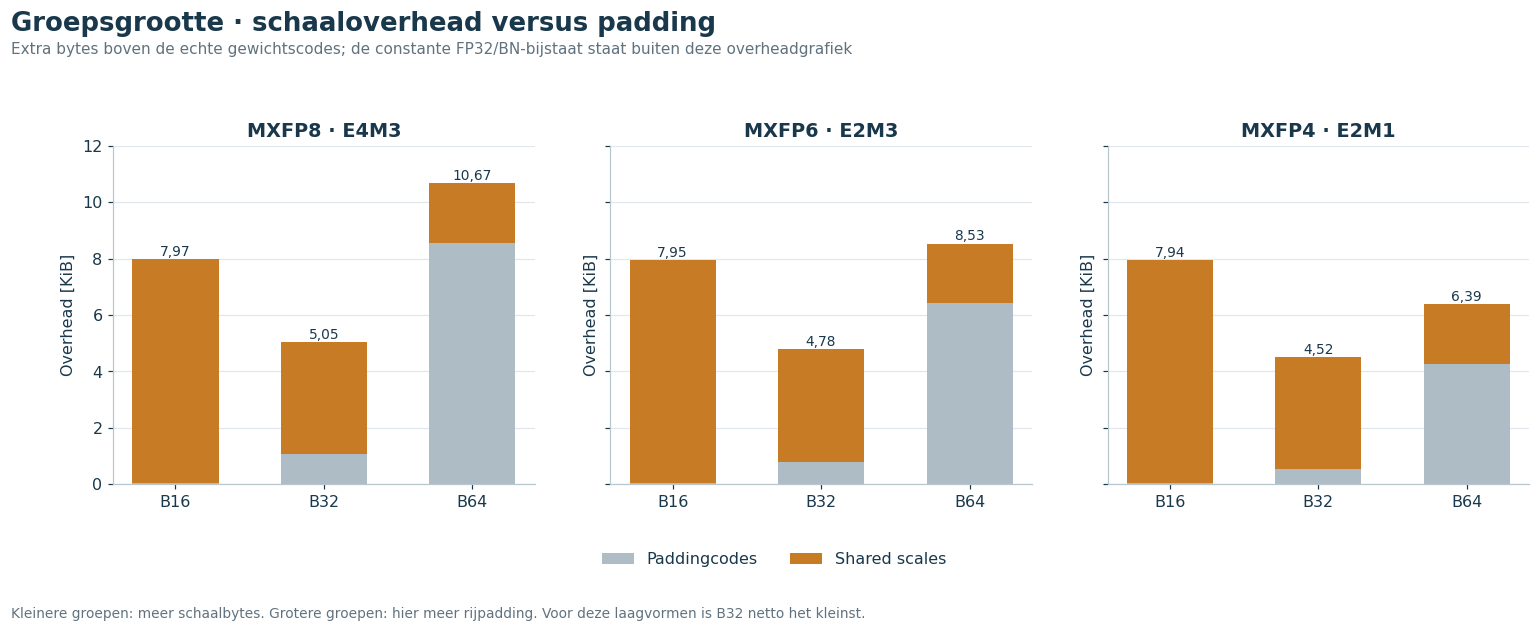

In [24]:
group_storage_plot()


B16/B32/B64 gebruiken respectievelijk **8.096 / 4.080 / 2.160 schaalbytes** en **64 / 1.088 / 8.768 paddingplaatsen**. Door de groepering per outputkanaal past B64 minder goed op deze laagvormen. B32 heeft daardoor voor alle drie formaten de kleinste totale payload. Deze uitkomst hangt samen met de gebruikte netwerkvormen en groeperingsas.

## 7.4 FP32-trainingsstaat en kosten van geleerde offsets


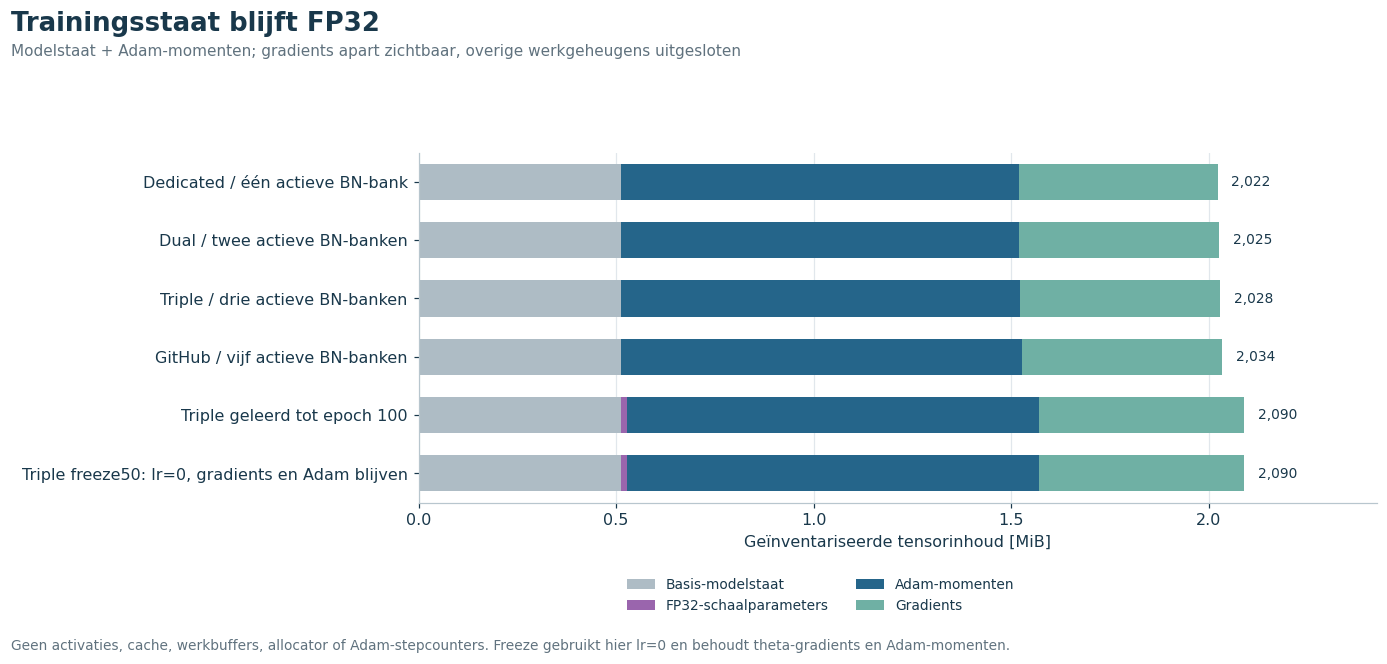

In [25]:
training_storage_plot()
table(pd.DataFrame(COST['training_state'])[['label','total_persistent_bytes','gradient_bytes','total_with_gradients_bytes']], 'Geïnventariseerde trainingstensors')


Voor de 4.080 geleerde theta’s komt **16.320 bytes parameterstaat**, **32.640 bytes Adam-momenten** en **16.320 bytes gradients** erbij: samen **65.280 bytes** boven de overeenkomstige triple-training. De vastgezette variant behoudt deze structuren in de huidige implementatie.

Dit tensorsubtotaal sluit activaties, quantisatiecaches, tijdelijke tensors, werkbuffers, allocator en Adam-stapcounters uit. Het kan dus niet rechtstreeks als totale GPU-geheugenbehoefte worden gelezen.

## 7.5 Gemeten tijd en verschillende aantallen passes


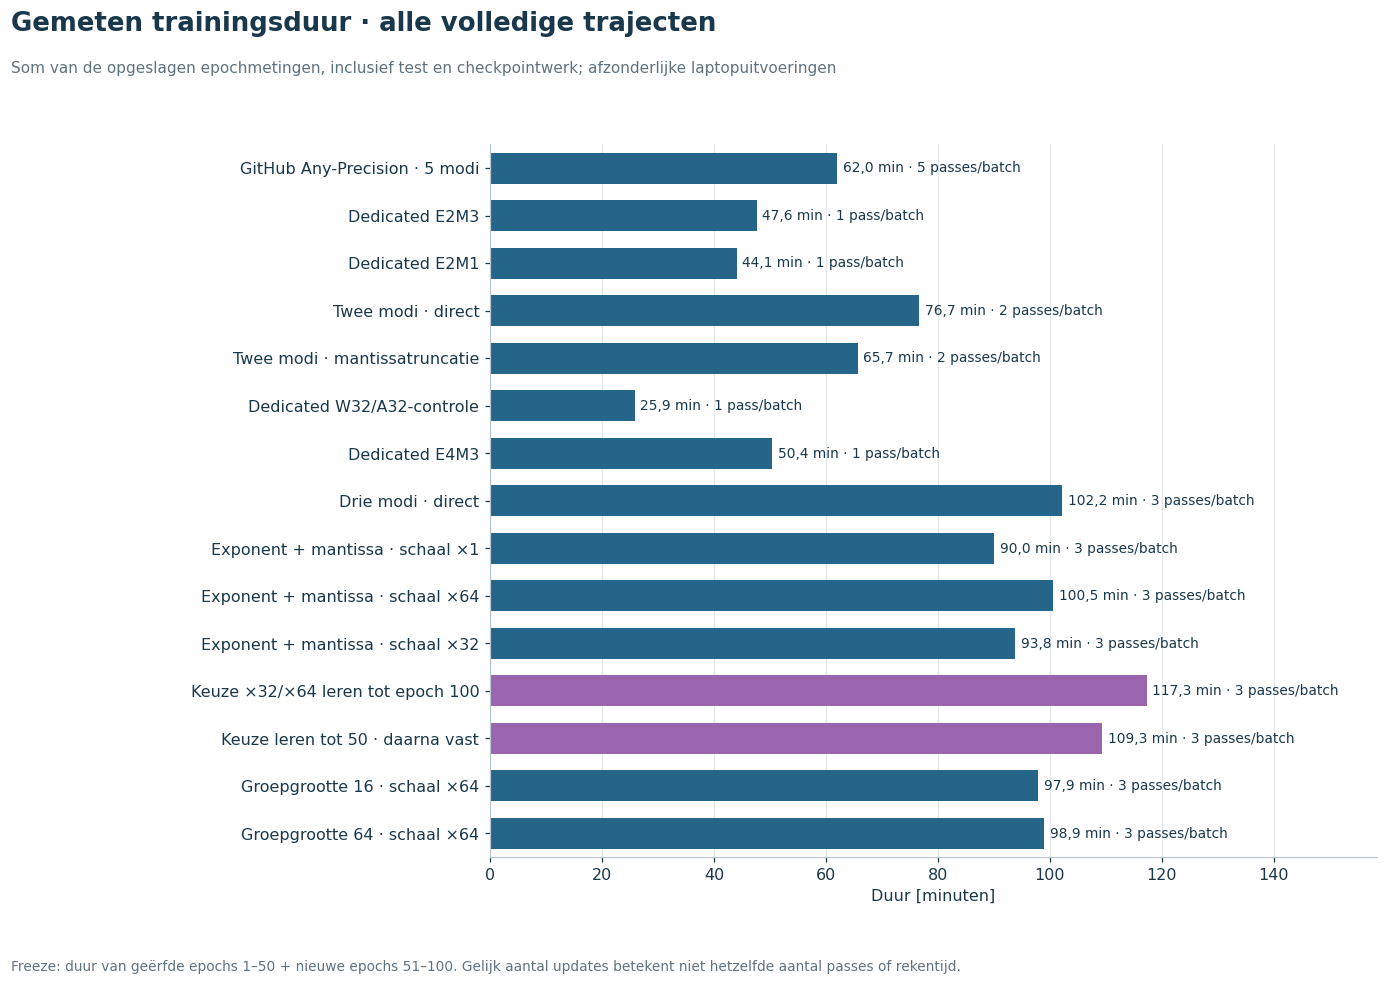

In [26]:
timing_plot()


Dedicated, dual en triple hebben evenveel optimizerupdates, maar respectievelijk één, twee en drie trainingspasses per minibatch. De GitHub-referentie heeft er vijf. De tijdvergelijking is beschrijvend: afzonderlijke laptopruns, verschillende loss-trajecten en geen gecontroleerde native-kernelbenchmark. Bij freeze is de weergegeven totale trajectduur samengesteld uit de geërfde eerste 50 epochs en de nieuwe laatste 50; de laatste hervatsessie alleen zou een onjuiste volledige-runvergelijking geven.


<a id="conclusies"></a>
# 8. Onderzoeksconclusies voor de meeting

1. **Mantissatruncatie is bruikbaar na voorbereiding tijdens training.** De achteraf toegepaste E2M3→E2M1-truncatie verlaagt de accuracy; het truncatiebewust getrainde tweemodusmodel herstelt een groot deel daarvan en ondersteunt uitvoering uit één compacte bron.
2. **Naïeve exponenttruncatie met ongewijzigde bronschaal is veel ingrijpender.** Training helpt, maar blijft bij ongeveer 86–87%. Het toevoegen van een vaste ×32- of ×64-relatie tijdens training brengt de onderzochte triple-modellen terug naar ongeveer 95%.
3. **De beste accuracy en de kleinste flexibele bron zijn verschillende doelen.** Triple-direct heeft hier de hoogste lagere-precisiescores, terwijl de truncatieroutes één E4M3-bron ondersteunen. Dat is de relevante hardware/software-afweging.
4. **De onderzochte binaire schaalkeuze leren geeft nog geen voordeel tegenover vaste factoren.** De keuze blijft laat in de training omslaan. Freeze na 50 verbetert de lage modi tegenover doorleren, maar blijft onder de vaste ×64-referentie op epoch 100.
5. **B32 blijft de beste praktische uitgangspositie binnen deze groepsproeven.** Het heeft zowel de beste eindaccuracies als de kleinste berekende payload. Eén run per variant bewijst geen algemeen optimum.

### Grenzen van het huidige bewijs

- Eén seed per methode; CUDA-uitvoering is niet bitexact gegarandeerd.
- De officiële testset wordt ook voor checkpointselectie gebruikt. De geselecteerde score is geen onafhankelijke testschatting.
- Dedicated en gezamenlijke trainingen verschillen in loss en aantal passes. Gewichten en BN veranderen samen; hun afzonderlijke bijdragen zijn niet gemeten.
- De resultaten betreffen statische SVHN-classificatie, geen reeds uitgevoerde continual-learning-proef.
- MX-activaties zijn niet getest. Alle MX-resultaten gebruiken A32 en FP32-updatemasters.
- Opslagberekeningen zijn expliciete layouts; snelheid en energie van native MX-hardware zijn niet gemeten.

### Mogelijke bespreekpunten met de begeleider

- Welke accuracyafname is acceptabel voor één compacte bron met meerdere uitvoerprecisies?
- B32 voorlopig behouden en tussenwaarden tussen ×32 en ×64 onderzoeken? Een factor als ×48 vraagt een extra representatiecomponent naast een gehele E8M0-offset; die proef is nog niet uitgevoerd.
- Wanneer zijn herhalingen met meerdere seeds of een aparte validatieset nodig om de kleinere verschillen te beoordelen?
- Welke volgende stap naar hardware of continual learning past bij de thesisdoelstelling?

Deze punten zijn voorstellen voor bespreking. Dit notebook start geen nieuwe experimenten.


<a id="bijlagen"></a>
# Bijlagen

## A. Checkpoints gekozen op de hoogste precisie

Alle modi van een gezamenlijke training komen uit **dezelfde geselecteerde epoch**. De dedicated modellen kiezen op hun eigen actieve precisie. Er worden geen afzonderlijke maxima van lagere modi gecombineerd tot een fictief gezamenlijk checkpoint.

Bij learned100 en freeze-na50 is de **globale** E4M3-selectie identiek: epoch 34, vóór het vertakken op epoch 50. Die selectie kan dus geen effect van freeze aantonen. Voor dat effect zijn epoch 100 en het verloop vanaf epoch 51 informatief; de beste E4M3-epoch binnen uitsluitend de frozen fase is 51.


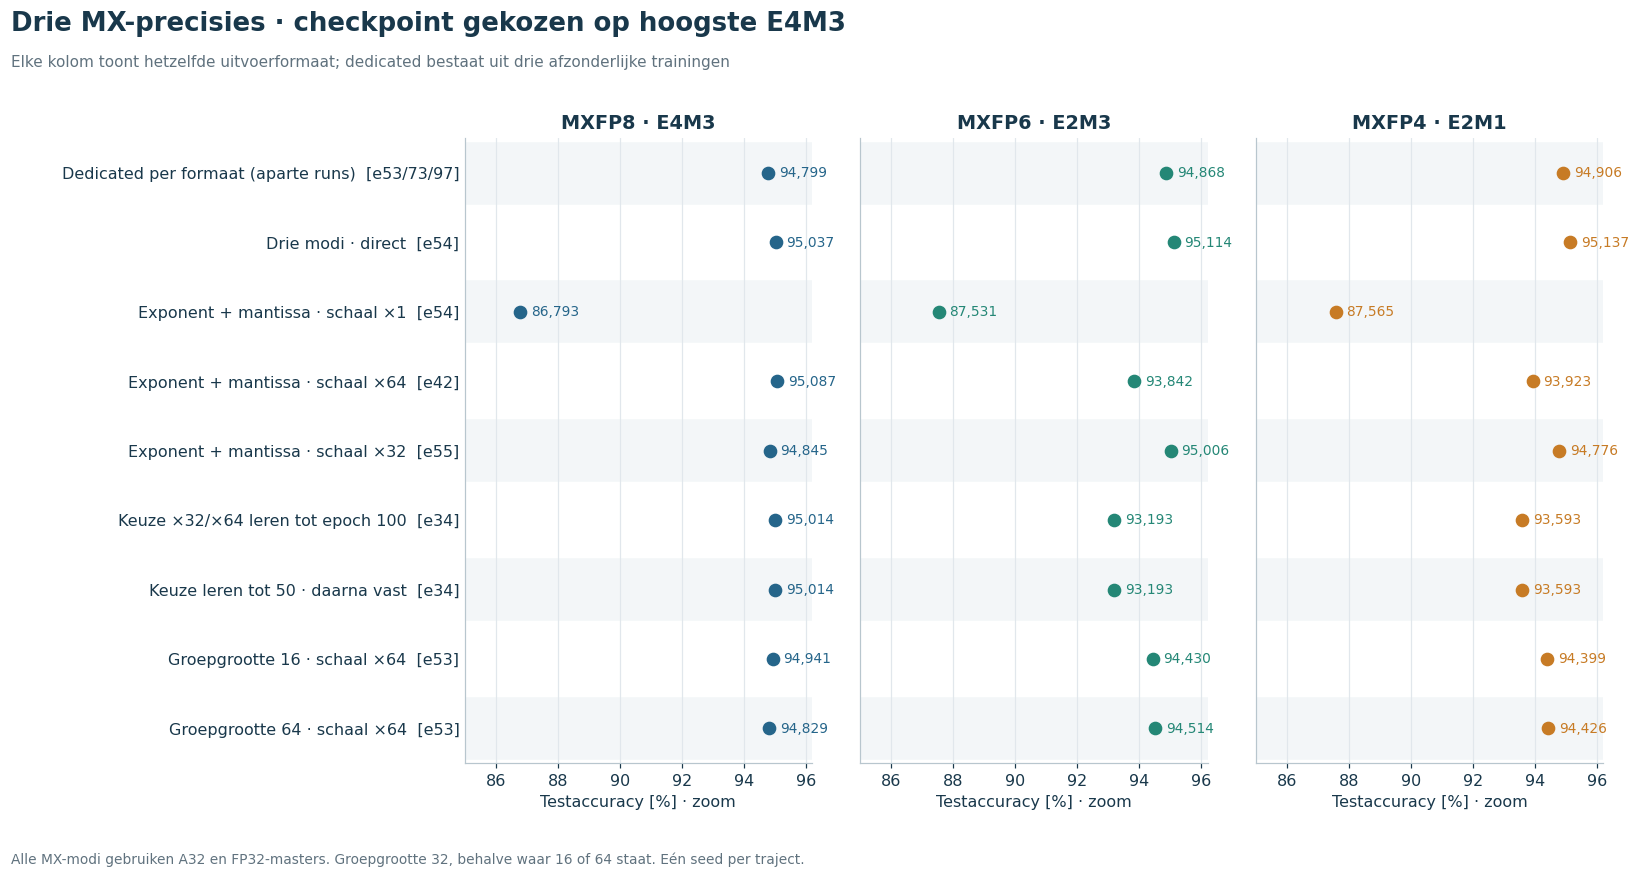

**Gezamenlijk geselecteerde triple-checkpoints**

,Training,Epoch,E4M3 [%],E2M3 [%],E2M1 [%]
0,Dedicated per formaat (aparte runs),53 / 73 / 97,94.798709,94.867855,94.906269
1,Drie modi · direct,54,95.036878,95.113706,95.136755
2,Exponent + mantissa · schaal ×1,54,86.793178,87.530731,87.565304
3,Exponent + mantissa · schaal ×64,42,95.086816,93.842194,93.922864
4,Exponent + mantissa · schaal ×32,55,94.844806,95.006146,94.775661
5,Keuze ×32/×64 leren tot epoch 100,34,95.013829,93.192993,93.592502
6,Keuze leren tot 50 · daarna vast,34,95.013829,93.192993,93.592502
7,Groepgrootte 16 · schaal ×64,53,94.940842,94.429932,94.399201
8,Groepgrootte 64 · schaal ×64,53,94.829441,94.514444,94.426091


In [27]:
triple_plot(role='selected', name='A1_triple_geselecteerd_checkpoint')
table(checkpoint_table(TRIPLE_IDS,role='selected'), 'Gezamenlijk geselecteerde triple-checkpoints', force=True)


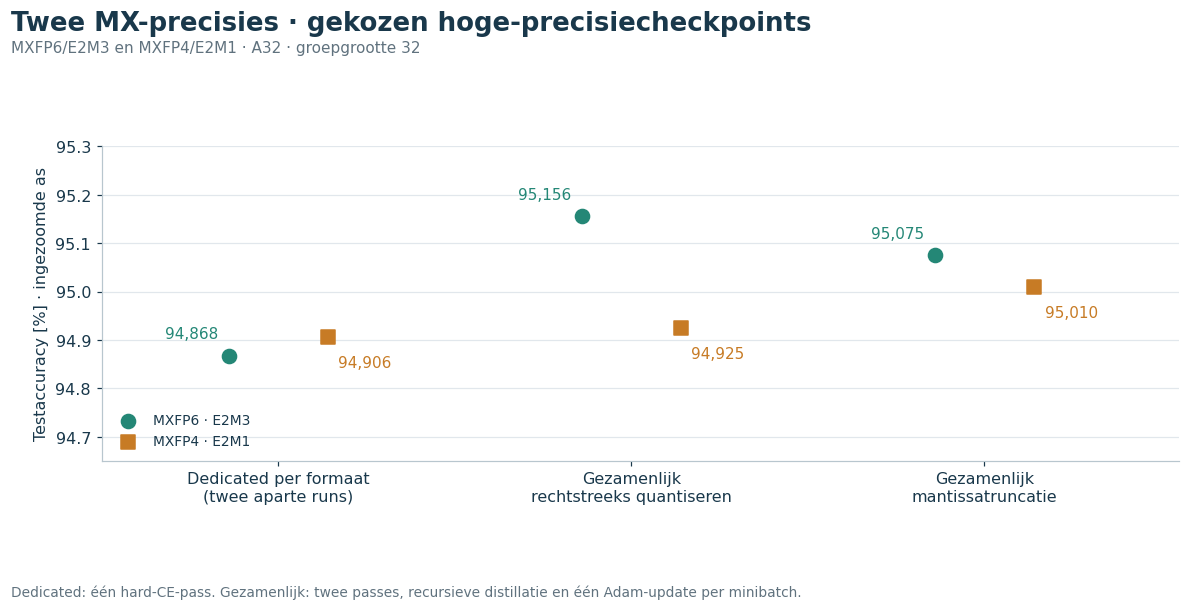

In [28]:
dual_plot(role='selected',name='A2_dual_geselecteerde_checkpoints')


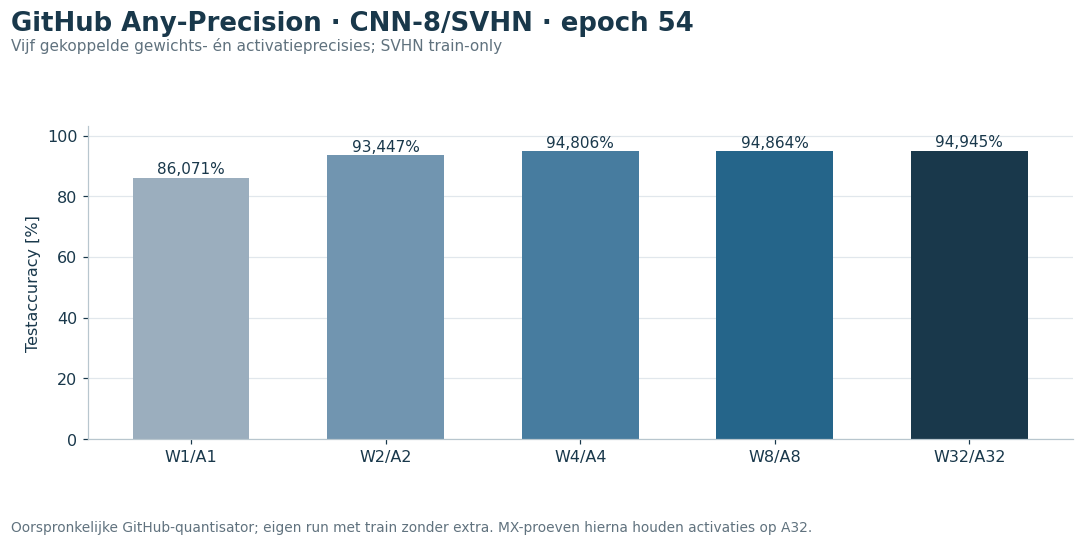

In [29]:
github_plot(role='selected',name='A3_github_geselecteerd_checkpoint')


## B. Posthocvergelijkingen op de geselecteerde checkpoints

Dezelfde evaluatiepaden staan hieronder op de oorspronkelijk geselecteerde checkpoints. De A/B/C-paden binnen één bron blijven gepaard. Bij de vergelijking met een apart getrainde variant kan de geselecteerde epoch verschillen; de tabel met volledige herkomst volgt verderop.


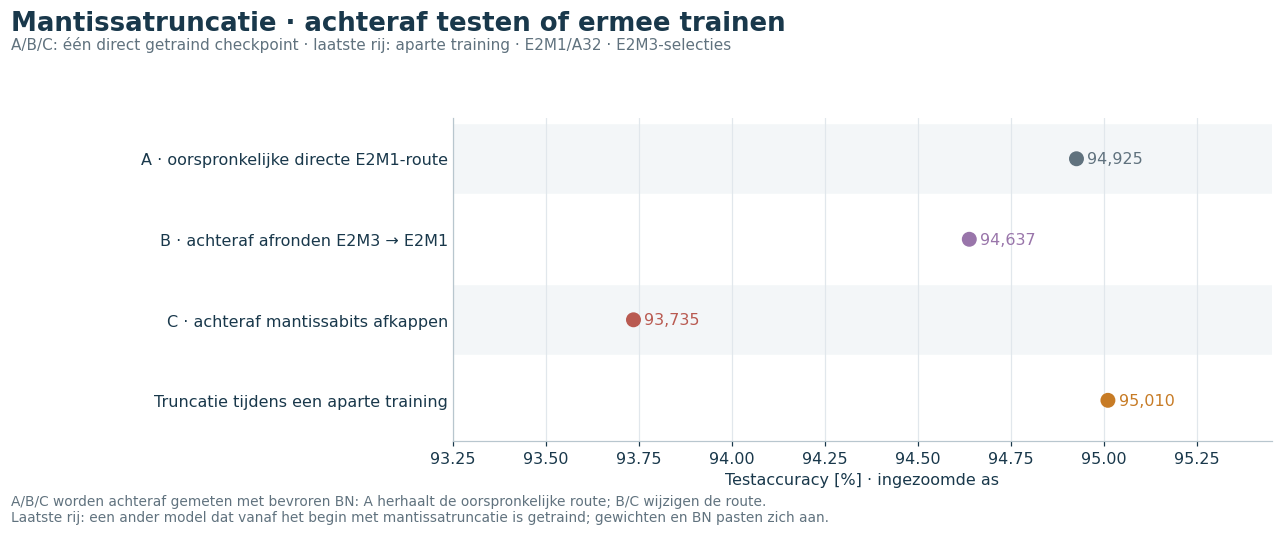

In [30]:
mantissa_plot(role='selected_high_precision',name='B1_mantissa_geselecteerd')


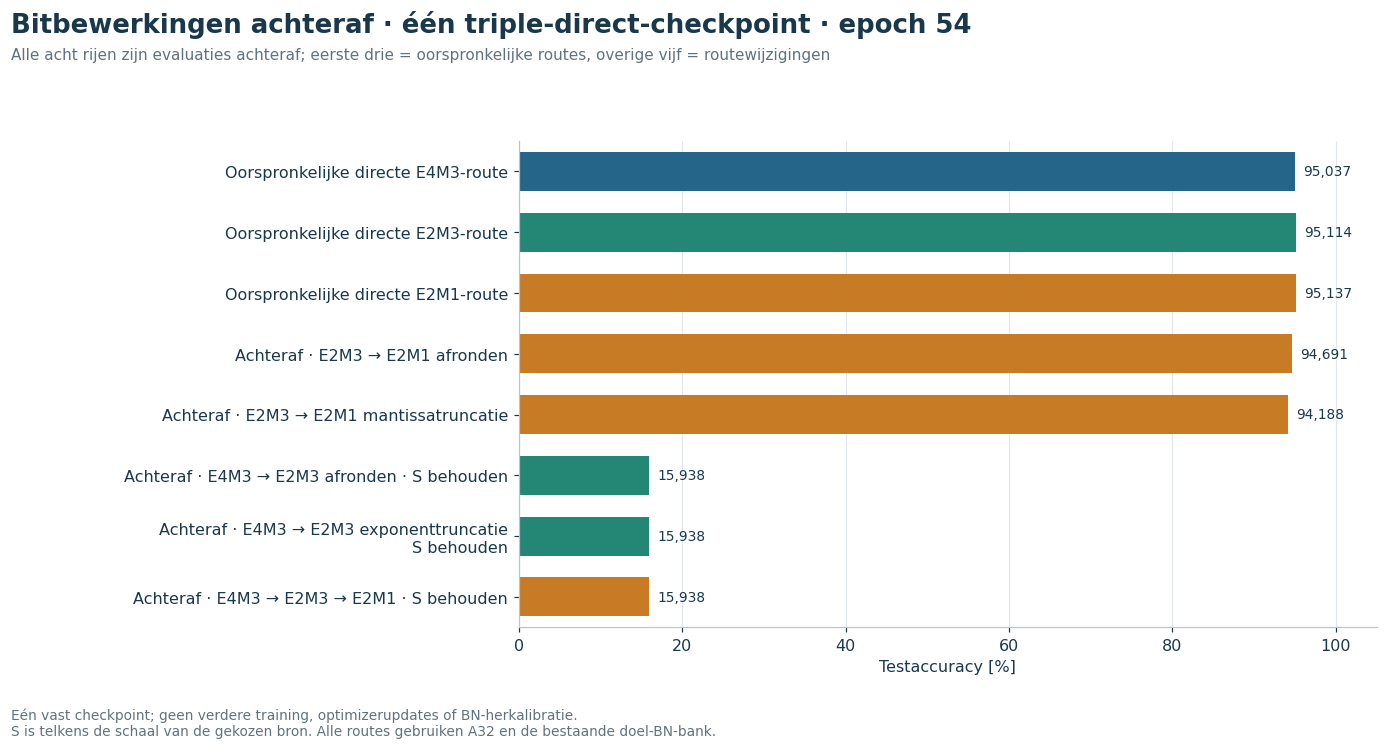

In [31]:
triple_posthoc_plot(role='selected_high_precision',name='B2_triple_bitbewerkingen_geselecteerd')


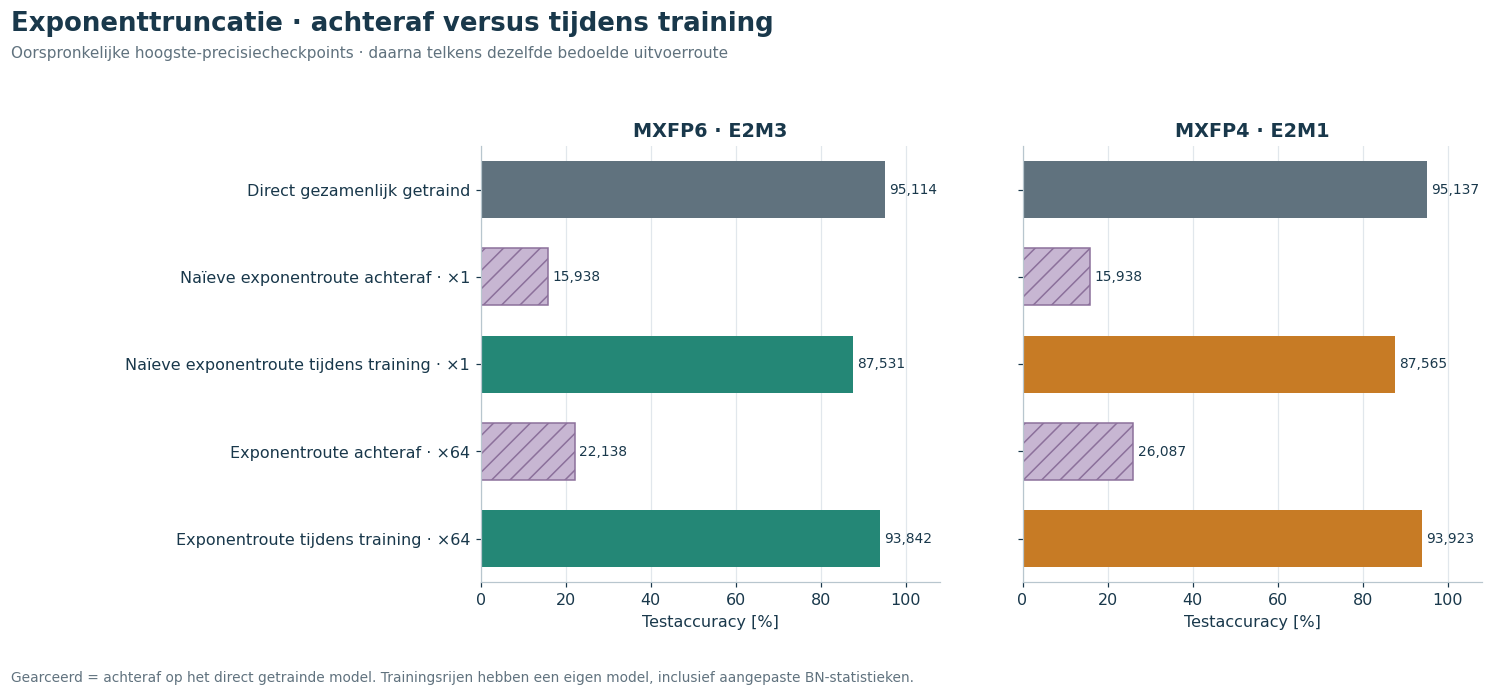

In [32]:
exponent_adaptation_plot(role='selected_high_precision',name='B3_exponent_geselecteerde_checkpoints')


## C. Controle na ×64-training en uitvoering uit één bron

De routewijziging achteraf na ×64-training bevestigt dat het model goed functioneert met de getrainde code- en schaalconfiguratie. Het vervangen daarvan door schaalbehoud of de afrondingscontrole kan accuracy verliezen. Dit is een reeds uitgevoerde controle; het motiveert hier geen extra herhaling van dezelfde training.


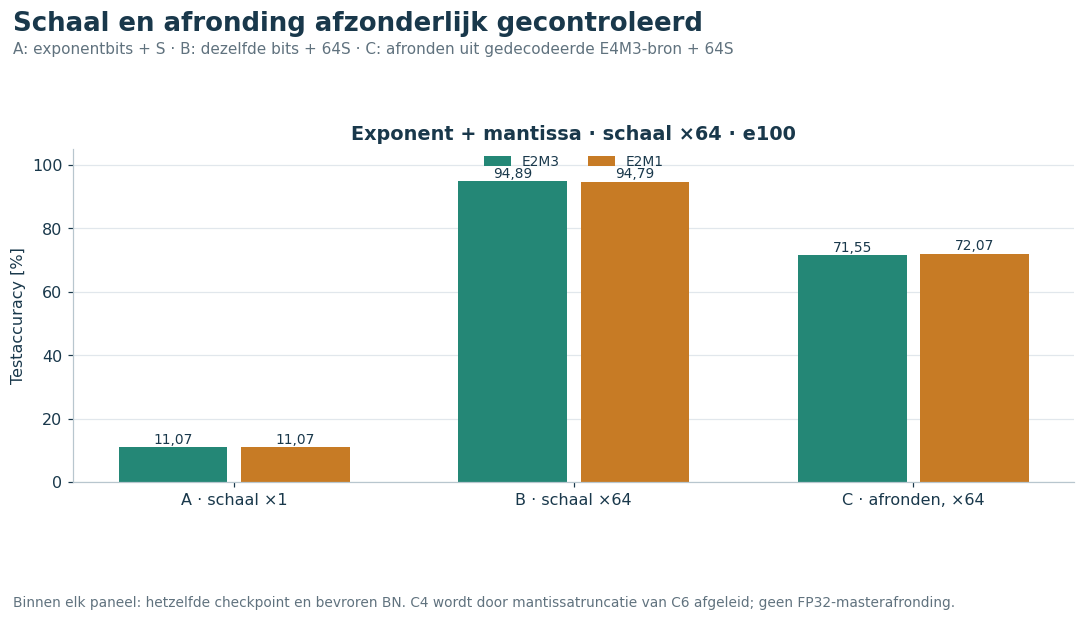

In [33]:
scale_control_plot(parents=('triple_scale64',),suite='scale64_trained_controls',name='C1_configuratie_na_schaal64_training')


De dual source-only-exportproef laadt uitsluitend de E2M3-bron met bijstaat en leidt E2M1 uit de broncodes af, zonder FP32-master, lage export of nieuwe encoder. De nieuwe testmeting verschilt één à twee correcte voorspellingen van de historische training. Ook de latere ×64-posthocmetingen verschillen soms één voorspelling. Daarom blijven **training en herhaalde evaluatie afzonderlijke meetrecords**.


In [34]:
table(posthoc_table().query("Proef == 'dual_source_only'"), 'Volledige source-only-evaluatie', force=True)


**Volledige source-only-evaluatie**

,Proef,Brontraining,Rol,Epoch,Route,Formaat,Accuracy [%],Correct,BN herkalibreerd,Bronbestand
16,dual_source_only,Twee modi · mantissatruncatie,selected_high_precision,52,E2M1 uitsluitend afgeleid uit E2M3-bron,E2M1,95.002305,24731,False,sources/posthoc/dual_source_only/metrics.csv
17,dual_source_only,Twee modi · mantissatruncatie,selected_high_precision,52,Opgeslagen E2M3-bron,E2M3,95.082975,24752,False,sources/posthoc/dual_source_only/metrics.csv
18,dual_source_only,Twee modi · mantissatruncatie,epoch100,100,E2M1 uitsluitend afgeleid uit E2M3-bron,E2M1,94.944683,24716,False,sources/posthoc/dual_source_only/metrics.csv
19,dual_source_only,Twee modi · mantissatruncatie,epoch100,100,Opgeslagen E2M3-bron,E2M3,94.967732,24722,False,sources/posthoc/dual_source_only/metrics.csv


## D. Alle exacte eindpunten, gekozen checkpoints en posthocmetingen

De tabellen hieronder geven de volledige geverifieerde meetwaarden en het aantal correcte testbeelden. `Correct / 26.032` controleert de gerapporteerde percentages. Zeer kleine floating-pointverschillen in de laatste decimalen van de historische percentages zijn behouden.


In [35]:
display(Markdown('### Alle oorspronkelijke epoch-100-scores'))
display(all_checkpoint_table())
display(Markdown('### Alle oorspronkelijke geselecteerde checkpoints'))
display(all_checkpoint_table(role='selected'))


### Alle oorspronkelijke epoch-100-scores

,Training,Modus,Epoch,Accuracy [%],Correct,Testbeelden,Selectieregel
0,GitHub Any-Precision · 5 modi,W32/A32,100,94.787185,24675,26032,first strict maximum of upstream W32/A32 test top1
1,GitHub Any-Precision · 5 modi,W8/A8,100,94.921635,24710,26032,first strict maximum of upstream W32/A32 test top1
2,GitHub Any-Precision · 5 modi,W4/A4,100,94.852489,24692,26032,first strict maximum of upstream W32/A32 test top1
3,GitHub Any-Precision · 5 modi,W2/A2,100,93.661647,24382,26032,first strict maximum of upstream W32/A32 test top1
4,GitHub Any-Precision · 5 modi,W1/A1,100,86.309158,22468,26032,first strict maximum of upstream W32/A32 test top1
5,Dedicated E2M3,MXFP6 · E2M3,100,94.825599,24685,26032,first strict maximum of active-mode official-test top1
6,Dedicated E2M1,MXFP4 · E2M1,100,94.821758,24684,26032,first strict maximum of active-mode official-test top1
7,Twee modi · direct,MXFP6 · E2M3,100,95.033036,24739,26032,first strict maximum of E2M3/A32 official-test top1
8,Twee modi · direct,MXFP4 · E2M1,100,95.025353,24737,26032,first strict maximum of E2M3/A32 official-test top1
9,Twee modi · mantissatruncatie,MXFP6 · E2M3,100,94.963891,24721,26032,first strict maximum of E2M3/A32 official-test top1


### Alle oorspronkelijke geselecteerde checkpoints

,Training,Modus,Epoch,Accuracy [%],Correct,Testbeelden,Selectieregel
0,GitHub Any-Precision · 5 modi,W32/A32,54,94.944683,24716,26032,first strict maximum of upstream W32/A32 test top1
1,GitHub Any-Precision · 5 modi,W8/A8,54,94.864014,24695,26032,first strict maximum of upstream W32/A32 test top1
2,GitHub Any-Precision · 5 modi,W4/A4,54,94.806392,24680,26032,first strict maximum of upstream W32/A32 test top1
3,GitHub Any-Precision · 5 modi,W2/A2,54,93.446527,24326,26032,first strict maximum of upstream W32/A32 test top1
4,GitHub Any-Precision · 5 modi,W1/A1,54,86.070990,22406,26032,first strict maximum of upstream W32/A32 test top1
5,Dedicated E2M3,MXFP6 · E2M3,73,94.867855,24696,26032,first strict maximum of active-mode official-test top1
6,Dedicated E2M1,MXFP4 · E2M1,97,94.906269,24706,26032,first strict maximum of active-mode official-test top1
7,Twee modi · direct,MXFP6 · E2M3,75,95.155962,24771,26032,first strict maximum of E2M3/A32 official-test top1
8,Twee modi · direct,MXFP4 · E2M1,75,94.925476,24711,26032,first strict maximum of E2M3/A32 official-test top1
9,Twee modi · mantissatruncatie,MXFP6 · E2M3,52,95.075292,24750,26032,first strict maximum of E2M3/A32 official-test top1


In [36]:
display(Markdown('### Alle 90 posthocmetingen'))
display(posthoc_table())


### Alle 90 posthocmetingen

,Proef,Brontraining,Rol,Epoch,Route,Formaat,Accuracy [%],Correct,BN herkalibreerd,Bronbestand
0,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,selected_high_precision,54,W32/A32-referentie,FP32,94.944683,24716,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
1,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,selected_high_precision,54,Wrapper met MX uit,FP32,94.944683,24716,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
2,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,selected_high_precision,54,MXFP6 achteraf,E2M3,94.960049,24720,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
3,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,selected_high_precision,54,MXFP6 uit opgeslagen export,E2M3,94.960049,24720,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
4,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,epoch100,100,W32/A32-referentie,FP32,94.787185,24675,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
5,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,epoch100,100,Wrapper met MX uit,FP32,94.787185,24675,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
6,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,epoch100,100,MXFP6 achteraf,E2M3,94.729564,24660,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
7,mx_cast_anyprecision,GitHub Any-Precision · 5 modi,epoch100,100,MXFP6 uit opgeslagen export,E2M3,94.729564,24660,False,sources/posthoc/mx_cast_anyprecision/metrics.csv
8,dual_mantissa,Twee modi · direct,selected_high_precision,75,Getrainde E2M3-bron,E2M3,95.155962,24771,False,sources/posthoc/dual_mantissa/metrics.csv
9,dual_mantissa,Twee modi · direct,selected_high_precision,75,Direct getrainde E2M1,E2M1,94.925476,24711,False,sources/posthoc/dual_mantissa/metrics.csv


## E. Opslagtabellen: één scope per tabel

De onderstaande tabellen koppelen elke trainingsmodus aan haar actieve payload en bronopslag. Voor de lage GitHub-integerprecisies is een gepakte native export **niet geïmplementeerd**. De theoretische code-layout telt naast de codes zes FP32-laagfactoren mee en blijft expliciet een scenario. Die nominale waarden worden niet als gemeten modelgrootte opgevoerd.

De gerapporteerde `.pt`-bestandsomvang bevat container- en metadata-overhead. De echte bestanden zijn hier niet opnieuw opgebouwd of ingelezen; hun omvang en SHA komen uit de oorspronkelijke exportregistraties.


In [37]:
display(pd.DataFrame(COST['per_run_costs'])[['label','format','active_model_bytes','nominal_active_model_bytes','flexible_source_bytes','training_persistent_bytes','reported_export_file_bytes']])
display(Markdown('### Nominale, ongebouwde GitHub-integerlayouts'))
display(pd.DataFrame(COST['nominal_integer_layouts']))
display(Markdown('### Gerapporteerde fysieke exportbestanden'))
display(pd.DataFrame(COST['reported_export_files']))


,label,format,active_model_bytes,nominal_active_model_bytes,flexible_source_bytes,training_persistent_bytes,reported_export_file_bytes
0,"GitHub Any-Precision, vijf gekoppelde W/A-modi",W32/A32,537136.000000,NaN,537136,1600768,NaN
1,"GitHub Any-Precision, vijf gekoppelde W/A-modi",W8/A8,NaN,148744.000000,537136,1600768,NaN
2,"GitHub Any-Precision, vijf gekoppelde W/A-modi",W4/A4,NaN,84008.000000,537136,1600768,NaN
3,"GitHub Any-Precision, vijf gekoppelde W/A-modi",W2/A2,NaN,51640.000000,537136,1600768,NaN
4,"GitHub Any-Precision, vijf gekoppelde W/A-modi",W1/A1,NaN,35456.000000,537136,1600768,NaN
5,Dedicated MXFP6 E2M3,E2M3,121248.000000,NaN,121248,1592576,163941.000000
6,Dedicated MXFP4 E2M1,E2M1,88608.000000,NaN,88608,1592576,131301.000000
7,"Gezamenlijk MXFP6 + MXFP4, rechtstreeks",E2M3,121248.000000,NaN,186528,1594624,163813.000000
8,"Gezamenlijk MXFP6 + MXFP4, rechtstreeks",E2M1,88608.000000,NaN,186528,1594624,131173.000000
9,"Gezamenlijk MXFP6 → MXFP4, mantissatruncatie",E2M3,121248.000000,NaN,121248,1594624,164005.000000


### Nominale, ongebouwde GitHub-integerlayouts

,id,format,weight_bits,n_weights,code_bytes,aux_bytes,nominal_code_plus_aux_bytes,hypothetical_fp32_layer_magnitude_bytes,nominal_model_bytes_with_magnitudes,native_packed_export_implemented,evidence,notes
0,github_w1_nominal,W1/A1,1,129472,16184,19248,35432,24,35456,False,Alleen analytische b-bit codes voor zes quantized convoluties; oorspronkelij...,Geen gemeten export of native low-bit opslag. De hypothetische 24 bytes zijn...
1,github_w2_nominal,W2/A2,2,129472,32368,19248,51616,24,51640,False,Alleen analytische b-bit codes voor zes quantized convoluties; oorspronkelij...,Geen gemeten export of native low-bit opslag. De hypothetische 24 bytes zijn...
2,github_w4_nominal,W4/A4,4,129472,64736,19248,83984,24,84008,False,Alleen analytische b-bit codes voor zes quantized convoluties; oorspronkelij...,Geen gemeten export of native low-bit opslag. De hypothetische 24 bytes zijn...
3,github_w8_nominal,W8/A8,8,129472,129472,19248,148720,24,148744,False,Alleen analytische b-bit codes voor zes quantized convoluties; oorspronkelij...,Geen gemeten export of native low-bit opslag. De hypothetische 24 bytes zijn...


### Gerapporteerde fysieke exportbestanden

,training_id,run_id,epoch,format,weight_bits,file,reported_file_bytes,reported_file_sha256,logical_active_model_bytes,reported_packed_choices_bytes,is_source_export_reported,derived_from_saved_source_reported,decoded_weights_exact_reported,six_fp32_masters_absent_reported,full_test_forward_rerun,source_report,source_report_sha256,evidence,caution
0,dedicated_mxfp6,20261017_190413_551517_mx_run,100,E2M3,6,mx_source_last.pt,163941,dcb3c4745d8336e72ae0d56faf044457aaca8a6f3388b44149085496b70360fe,121248,0,None,None,True,True,False,work/meeting20261029_research/baseline_dual_audit/sources/dedicated_mxfp6/ru...,e9cbbc16f4168c3ebb6de0f1c7bf1162b913c81de1934a969ed87f22874ad872,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
1,dedicated_mxfp4,20261021_182608_167996_mx_run,100,E2M1,4,mx_source_last.pt,131301,9a1aa9c781cef585e83680e25d52bf7e84d44a3a0db08d444bc556d22520d9f1,88608,0,None,None,True,True,False,work/meeting20261029_research/baseline_dual_audit/sources/dedicated_mxfp4/ru...,9d192214376689a0f39547ddad3162132d997312f3afed74e880acf0677c085d,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
2,dual_direct,20261019_192538_709626_joint_run,100,E2M3,6,mx_direct_MXFP6_E2M3_last.pt,163813,1e867aa3611ef3429e549857d787f4b3c8c80a58885738410918cf6773fea986,121248,0,None,None,True,True,False,work/meeting20261029_research/baseline_dual_audit/sources/dual_direct/run_re...,a2f95bf189060087fa3a757e06a28bf0fbdf04d6939bfc6bb78f30bc4389652e,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
3,dual_direct,20261019_192538_709626_joint_run,100,E2M1,4,mx_direct_MXFP4_E2M1_last.pt,131173,af80123d284345f7d90f99197a111f66238bde5da109596aff6f0302584a490f,88608,0,None,None,True,True,False,work/meeting20261029_research/baseline_dual_audit/sources/dual_direct/run_re...,a2f95bf189060087fa3a757e06a28bf0fbdf04d6939bfc6bb78f30bc4389652e,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
4,dual_mantissa,20261021_153559_999222_joint_run,100,E2M3,6,mx_source_E2M3_last.pt,164005,d770544c269777e8f9d7d60c0da6b45c098424b7efbf6f98c19ff2313a851422,121248,0,None,None,True,True,False,work/meeting20261029_research/baseline_dual_audit/sources/dual_mantissa/run_...,8d58e6fb56c8fa49894306cbccbc165b05b5667aafd0d13ea498f82b38ce461c,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
5,dual_mantissa,20261021_153559_999222_joint_run,100,E2M1,4,mx_derived_E2M1_last.pt,131621,7f7f3e836fd49ee0ecd54f04d2aa6f03dba0574f5e31398ef8bde940a70654e9,88608,0,None,None,True,True,False,work/meeting20261029_research/baseline_dual_audit/sources/dual_mantissa/run_...,8d58e6fb56c8fa49894306cbccbc165b05b5667aafd0d13ea498f82b38ce461c,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
6,dedicated_e4m3,20261023_132558_081080_mx_run,100,E4M3,8,mx_source_last.pt,196581,3960d10e786579806b72b4dc4a31bda8e0f76478123086c2069cd13959bfd752,153888,0,None,None,True,True,False,work/meeting20261029_research/triple_audit/raw/dedicated_e4m3/run_report.json,12118850ee093fa17ed91aaf1d31a985d73960bd878186daaf4db27c980b2d89,Bestandsomvang en SHA256 gemeten door de echte trainingsexport en opgenomen ...,"Containerbytes zijn geen logische payload, trainingsstate of VRAM. De presen..."
7,triple_direct,20261023_151331_732669_joint_run,100,E4M3,8,mx_direct_MXFP8_E4M3_last.pt,196517,d692c4b293ea924281ffd1698020bd8cff2a486f663ee62babf24c5f6afbec9d,153888,0,None,None,True,Tr

## F. Herkomst en reproduceerbaarheid

Alle grafieken gebruiken ingesloten geverifieerde gegevens, met oorspronkelijke run-ID’s, checkpointrollen en hashes. De optionele bronnen-ZIP bevat **154 ongewijzigde primaire bestanden**, een bronmanifest en de kostentabellen. De notebook controleert bij uitvoering haar eigen datahash, complete metricreeksen, correcte aantallen en de gedeelde checkpointselectie. Zij voert geen training of nieuwe modelevaluatie uit.

De vorige meetingnotebook is gebruikt als structuur- en bronreferentie. Verouderde openstaande punten zijn bijgewerkt: de source-only-exportproef is inmiddels uitgevoerd. Vijf-epochpilots worden niet als epoch-100-resultaat meegeteld; zij waren aparte controles van de training en software.

**Broncode in het aanvullende pakket:** [CNN-8](sources/model/svhn_quan.py), [oorspronkelijke quantisatoren](sources/model/original_quan_ops.py), [oorspronkelijke training](sources/model/original_train.py) en [tensorinventaris](sources/model/tensorinventaris.json). Deze relatieve bronlinks werken na uitpakken van het volledige pakket; de losse notebook heeft die bestanden niet nodig om te draaien.


In [38]:
display(source_table())
display(Markdown('### Auditoverzicht'))
display(pd.DataFrame([DATA['audit']]))


,Training,Oorspronkelijke run,Feedbackbundel,Metrics,SHA-256 metrics
0,GitHub Any-Precision · 5 modi,20261016_165710_766662_run,feedback_bundle(3).zip,sources/training/github_anyprecision5/epoch_metrics.csv,64c1b4765bcdb53685f3fec316f926efc4bf1dca469cd003cb21066e8793591a
1,Dedicated E2M3,20261017_190413_551517_mx_run,feedback_bundle(9).zip,sources/training/dedicated_mxfp6/epoch_metrics.csv,fc96fcb071fbb4fe480d88995310dadeda8eb619a3f428bd0b25a2bf870f33ea
2,Dedicated E2M1,20261021_182608_167996_mx_run,feedback_bundle(20261021-171049).zip,sources/training/dedicated_mxfp4/epoch_metrics.csv,5e526a4c2633a97e37087802e3212b5a7ecb1d2e0e4612b0154da91172abae00
3,Twee modi · direct,20261019_192538_709626_joint_run,feedback_bundle(20261019-184806).zip,sources/training/dual_direct/epoch_metrics.csv,8c3b1f07ed92d69f89bdedf72ca3b610c53a2cf11eb72fefb03bdb641ed07dbb
4,Twee modi · mantissatruncatie,20261021_153559_999222_joint_run,feedback_bundle(20261021-144630).zip,sources/training/dual_mantissa/epoch_metrics.csv,bdc13e22203c90ff9b81a8a3b284212cb313a4d5c786c0c63c9ab9cea425c3a7
5,Dedicated W32/A32-controle,20261017_182916_351453_control_run,feedback_bundle(10).zip,sources/training/dedicated_w32_control/epoch_metrics.csv,deced184ff205ecb42ab43bec6af2da5ff7a7dcc0628b9a08b813255e86f110e
6,Dedicated E4M3,20261023_132558_081080_mx_run,feedback_bundle(20261023-121902).zip,sources/training/dedicated_e4m3/epoch_metrics.csv,048305dbf277809c7a68d01cb3588f0063933bbd92276fc31129e2dbb7a976cd
7,Drie modi · direct,20261023_151331_732669_joint_run,feedback_bundle(20261023-150530).zip,sources/training/triple_direct/epoch_metrics.csv,52df99915d90f3626399db078f610ac4a2ada7658052eed37ed76a7cd0a006c8
8,Exponent + mantissa · schaal ×1,20261023_184058_211397_joint_run,feedback_bundle(20261023-181200).zip,sources/training/triple_naive/epoch_metrics.csv,a9ec9ac706b75af6c7144da6ded18286cf676cdee724444892974c627d2bd337
9,Exponent + mantissa · schaal ×64,20261024_151210_665535_joint_run,feedback_bundle(20261024-145841).zip,sources/training/triple_scale64/epoch_metrics.csv,cb6c9ddcff6c263bf24c3cde3b02bab8ead694ae21e278b58d1632bf67ce60ab


### Auditoverzicht

,status,upstream_checks,source_files_verified_exact,independently_recounted_posthoc_per_image_archives,limitations
0,PASS,"{'baseline_dual': 20027, 'triple': 50305, 'posthoc': 1325}",True,10,[Standard GitHub five-mode run changes both W and A. MX experiments change o...


## G. Figuren bewaren

Zet bovenaan `SAVE_FIGURES=True` en voer het notebook opnieuw uit om alle figuren als PNG en SVG te bewaren in een **nieuwe map**. De exacte aan de figuren gekoppelde meetwaarden worden als JSON mee opgeslagen. Met de standaardinstelling worden alleen de figuren in het notebook getoond.


In [39]:
export_figures()


28 figuren getoond. SAVE_FIGURES=False: geen bestanden geschreven.
